In [3]:
# Import necessary libraries


import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import re
import missingno as msno

from loan_default.config import ID_COL, RANDOM_SEED, TARGET
from loan_default.data.load import load_raw, train_test_stratified


pd.set_option("display.max_rows", None)


In [4]:
# Load the raw data
df = load_raw()

df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# Structure and Sanity

In [5]:
df.shape

(307511, 122)

In [6]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 325.2 MB


In [8]:
df.memory_usage(deep=True)

Index                                132
SK_ID_CURR                       2460088
TARGET                           2460088
NAME_CONTRACT_TYPE               5681593
CODE_GENDER                      2767607
FLAG_OWN_CAR                     2767599
FLAG_OWN_REALTY                  2767599
CNT_CHILDREN                     2460088
AMT_INCOME_TOTAL                 2460088
AMT_CREDIT                       2460088
AMT_ANNUITY                      2460088
AMT_GOODS_PRICE                  2460088
NAME_TYPE_SUITE                  6189462
NAME_INCOME_TYPE                 5784774
NAME_EDUCATION_TYPE             10225644
NAME_FAMILY_STATUS               5419226
NAME_HOUSING_TYPE                7626199
REGION_POPULATION_RELATIVE       2460088
DAYS_BIRTH                       2460088
DAYS_EMPLOYED                    2460088
DAYS_REGISTRATION                2460088
DAYS_ID_PUBLISH                  2460088
OWN_CAR_AGE                      2460088
FLAG_MOBIL                       2460088
FLAG_EMP_PHONE  

In [9]:
df.dtypes.value_counts()

float64    65
int64      41
str        16
Name: count, dtype: int64

In [10]:
int_cols = df.select_dtypes(include="int").columns
binary_flags = [c for c in int_cols if df[c].nunique(dropna=True) == 2]
numeric_cols = [c for c in df.select_dtypes(include="number").columns if c not in binary_flags]
object_cols = df.select_dtypes(include="object").columns

print(f"Numeric (non-binary) : {len(numeric_cols)}")
print(f"Object: {len(object_cols)}")
print(f"Binary flags: {len(binary_flags)}")
print(f"Total columns: {len(df.columns)}")

Numeric (non-binary) : 73
Object: 16
Binary flags: 33
Total columns: 122


C:\Users\Aditya\AppData\Local\Temp\ipykernel_20196\3163516812.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include="object").columns


# 2. Target Analysis

In [11]:
df["TARGET"].value_counts(normalize=True)*100

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

Accuracy is misleading here because always predicting 0 gives ~92%. We'll use ROC-AUC, PR-AUC, and recall/precision on the default class.

# 3. Missing Values

In [12]:
PLACEHOLDERS = {"xna", "unknown", "n/a", "na", "?", "", "none", "null", "nan"}

found = {}
for col in object_cols:
    cleaned = df[col].dropna().astype(str).str.strip().str.lower()  # normalise the text
    hits = cleaned.isin(PLACEHOLDERS)                               # True where it matches a placeholder
    if hits.any():
        found[col] = {"n missing":hits.sum(),"PLACEHOLDERS":cleaned[hits].unique().tolist()}

found


{'CODE_GENDER': {'n missing': np.int64(4), 'PLACEHOLDERS': ['xna']},
 'NAME_FAMILY_STATUS': {'n missing': np.int64(2), 'PLACEHOLDERS': ['unknown']},
 'ORGANIZATION_TYPE': {'n missing': np.int64(55374), 'PLACEHOLDERS': ['xna']}}

In [13]:

int_cols = df.select_dtypes(include="int").columns
binary_flags = [c for c in int_cols if df[c].nunique(dropna=True) == 2]
numeric_cols = [
    c for c in df.select_dtypes(include="number").columns if c not in binary_flags and c not in (ID_COL, TARGET)
]

rows = []
for c in numeric_cols:
    vc = df[c].value_counts(normalize=True)
    
    rows.append({
        "col":c,
        "top_value": vc.index[0],
        "top_share_%":100 * vc.iloc[0],
        "second_share_%": 100 * vc.iloc[1] if len(vc) > 1 else 0.0,
    })
scan = pd.DataFrame(rows)
spike = scan[(scan["top_share_%"] >= 5) & (scan["top_share_%"] >= 3 * scan["second_share_%"])]
print(f"{len(spike)} numeric columns have a dominant value; {(spike.top_value == 0).sum()} are zero-heavy counts (usually genuine)")
print("\nDominant value that is NOT zero (candidates):")
display(spike[spike.top_value != 0].round(2))

days_cols = [c for c in df.columns if c.startswith("DAYS_")]
print("DAYS_* columns with positive values(they should be <=0);",{c:int((df[c] > 0).sum()) for c in days_cols if (df[c] > 0).any()})



32 numeric columns have a dominant value; 29 are zero-heavy counts (usually genuine)

Dominant value that is NOT zero (candidates):


,col,top_value,top_share_%,second_share_%
7,DAYS_EMPLOYED,365243.0,18.01,0.05
12,REGION_RATING_CLIENT,2.0,73.81,15.72
13,REGION_RATING_CLIENT_W_CITY,2.0,74.63,14.26


DAYS_* columns with positive values(they should be <=0); {'DAYS_EMPLOYED': 55374}


In [14]:
df.isna().sum().sort_values(ascending=False).where(lambda x: x > 0).dropna()

COMMONAREA_AVG                  214865.0
COMMONAREA_MODE                 214865.0
COMMONAREA_MEDI                 214865.0
NONLIVINGAPARTMENTS_MEDI        213514.0
NONLIVINGAPARTMENTS_MODE        213514.0
NONLIVINGAPARTMENTS_AVG         213514.0
FONDKAPREMONT_MODE              210295.0
LIVINGAPARTMENTS_AVG            210199.0
LIVINGAPARTMENTS_MEDI           210199.0
LIVINGAPARTMENTS_MODE           210199.0
FLOORSMIN_MODE                  208642.0
FLOORSMIN_AVG                   208642.0
FLOORSMIN_MEDI                  208642.0
YEARS_BUILD_AVG                 204488.0
YEARS_BUILD_MODE                204488.0
YEARS_BUILD_MEDI                204488.0
OWN_CAR_AGE                     202929.0
LANDAREA_MEDI                   182590.0
LANDAREA_AVG                    182590.0
LANDAREA_MODE                   182590.0
BASEMENTAREA_MODE               179943.0
BASEMENTAREA_MEDI               179943.0
BASEMENTAREA_AVG                179943.0
EXT_SOURCE_1                    173378.0
NONLIVINGAREA_MO

In [15]:
n = df.isna().sum()
pct = df.isna().mean().mul(100)

df_missing_cols = pd.DataFrame({"n_missing":n,"pct_missing":pct}).query("n_missing > 0").sort_values("n_missing",ascending=False).rename_axis("col_name").reset_index()

df_missing_cols


,col_name,n_missing,pct_missing
0,COMMONAREA_MEDI,214865,69.872297
1,COMMONAREA_MODE,214865,69.872297
2,COMMONAREA_AVG,214865,69.872297
3,NONLIVINGAPARTMENTS_MODE,213514,69.432963
4,NONLIVINGAPARTMENTS_MEDI,213514,69.432963
5,NONLIVINGAPARTMENTS_AVG,213514,69.432963
6,FONDKAPREMONT_MODE,210295,68.386172
7,LIVINGAPARTMENTS_AVG,210199,68.354953
8,LIVINGAPARTMENTS_MEDI,210199,68.354953
9,LIVINGAPARTMENTS_MODE,210199,68.354953


In [16]:
def missing_col_bucket(pct_missing):
    if pct_missing == 0:
        return "0%"
    elif pct_missing <= 5:
        return "0-5%"
    elif pct_missing <= 10:
        return "5-10%"
    elif pct_missing <= 20:
        return "10-20%"
    elif pct_missing <= 30:
        return "20-30%"
    elif pct_missing <= 50:
        return "30-50%"
    else:
        return ">50%"
    
missing_pct_bucket = df_missing_cols["pct_missing"].apply(missing_col_bucket).value_counts().sort_index()

In [17]:
high_missing = df_missing_cols[df_missing_cols["pct_missing"] > 50].sort_values(by="pct_missing", ascending=False)
HIGH_MISSING_COLS = high_missing.col_name
print(f"Columns with >50% missing values: {HIGH_MISSING_COLS}")

Columns with >50% missing values: 0              COMMONAREA_MEDI
1              COMMONAREA_MODE
2               COMMONAREA_AVG
3     NONLIVINGAPARTMENTS_MODE
4     NONLIVINGAPARTMENTS_MEDI
5      NONLIVINGAPARTMENTS_AVG
6           FONDKAPREMONT_MODE
7         LIVINGAPARTMENTS_AVG
8        LIVINGAPARTMENTS_MEDI
9        LIVINGAPARTMENTS_MODE
10              FLOORSMIN_MEDI
11              FLOORSMIN_MODE
12               FLOORSMIN_AVG
13            YEARS_BUILD_MODE
14            YEARS_BUILD_MEDI
15             YEARS_BUILD_AVG
16                 OWN_CAR_AGE
17                LANDAREA_AVG
18               LANDAREA_MEDI
19               LANDAREA_MODE
20           BASEMENTAREA_MODE
21           BASEMENTAREA_MEDI
22            BASEMENTAREA_AVG
23                EXT_SOURCE_1
24          NONLIVINGAREA_MEDI
25           NONLIVINGAREA_AVG
26          NONLIVINGAREA_MODE
27              ELEVATORS_MEDI
28              ELEVATORS_MODE
29               ELEVATORS_AVG
30          WALLSMATERIAL_MODE
31   

In [18]:
HOUSING_TOKENS = ("_AVG", "_MODE", "_MEDI")

def group_columns(columns):
    groups = {
        "Housing": [],
        "EXT_SOURCE": [],
        "AMT_REQ_CREDIT_BUREAU": [],
        "SOCIAL_CIRCLE": [],
        "OTHERS": [],
    }
    
    for c in columns:
        if any(token in c for token in HOUSING_TOKENS):
            groups["Housing"].append(c)
        elif c.startswith("EXT_SOURCE"):
            groups["EXT_SOURCE"].append(c)
        elif c.startswith("AMT_REQ_CREDIT_BUREAU"):
            groups["AMT_REQ_CREDIT_BUREAU"].append(c)
        elif c.startswith("DEF_") or c.startswith("OBS_"):
            groups["SOCIAL_CIRCLE"].append(c)
        else:
            groups["OTHERS"].append(c)
    
    return groups

grouped_cols = group_columns(df_missing_cols["col_name"])
print(f"Housing: {len(grouped_cols['Housing'])}")
print(f"EXT_SOURCE: {len(grouped_cols['EXT_SOURCE'])}")
print(f"AMT_REQ_CREDIT_BUREAU: {len(grouped_cols['AMT_REQ_CREDIT_BUREAU'])}")
print(f"SOCIAL_CIRCLE: {len(grouped_cols['SOCIAL_CIRCLE'])}")
print(f"OTHERS: {len(grouped_cols['OTHERS'])}")

Housing: 47
EXT_SOURCE: 3
AMT_REQ_CREDIT_BUREAU: 6
SOCIAL_CIRCLE: 4
OTHERS: 7


## 3.1 Columns that are missing together
- Do some columns share exactly (or almost) the same missing rows?
- Check one example group (for example the three `COMMONAREA_*` columns) by comparing their `isna()` masks.
- Investigate a few examples, not every column.

**What I see:**

In [19]:
m_avg = df["COMMONAREA_AVG"].isna()
m_mode = df["COMMONAREA_MODE"].isna()
m_medi = df["COMMONAREA_MEDI"].isna()

(m_avg != m_mode).sum()
(m_avg != m_medi).sum()

np.int64(0)

COMMONAREA_* columns share exactly the same missing rows

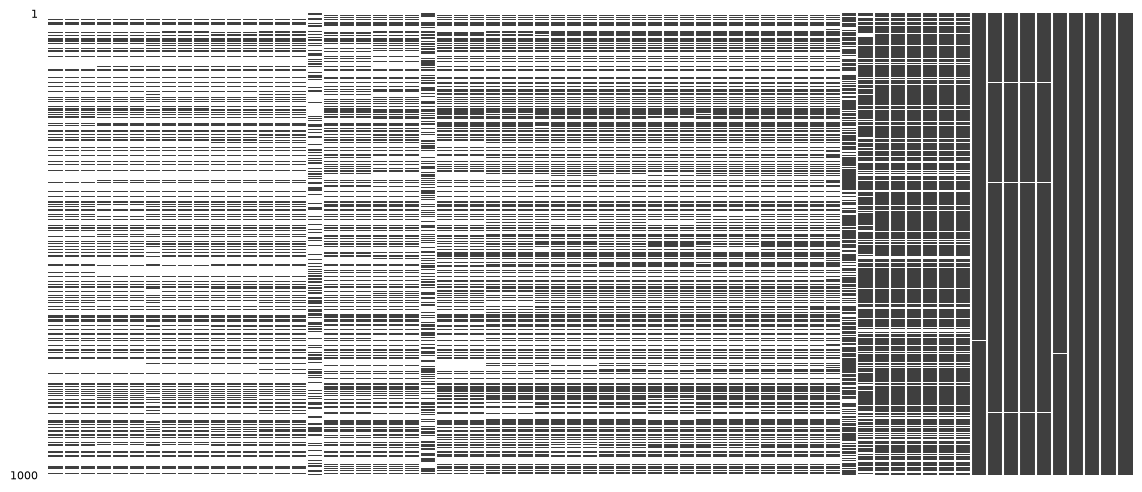

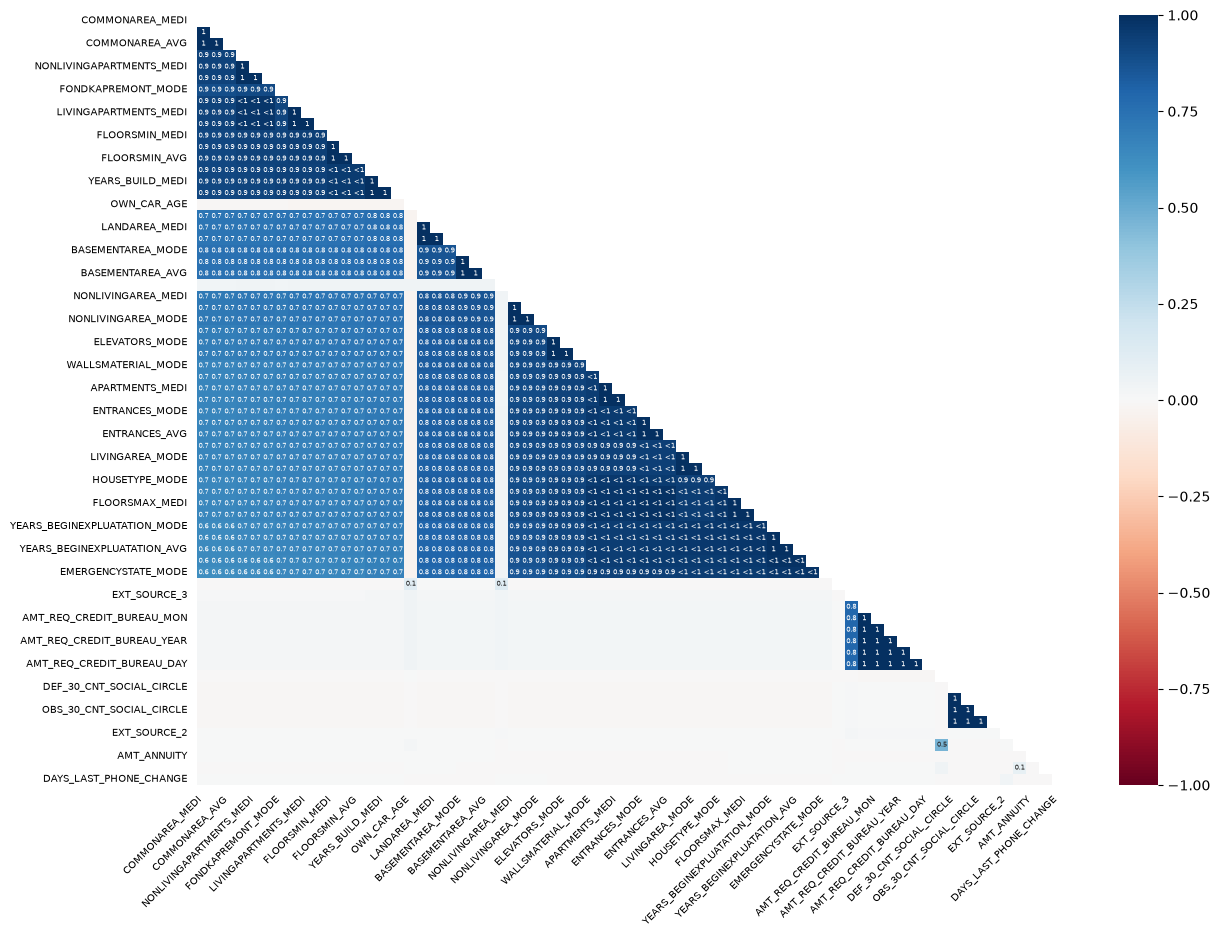

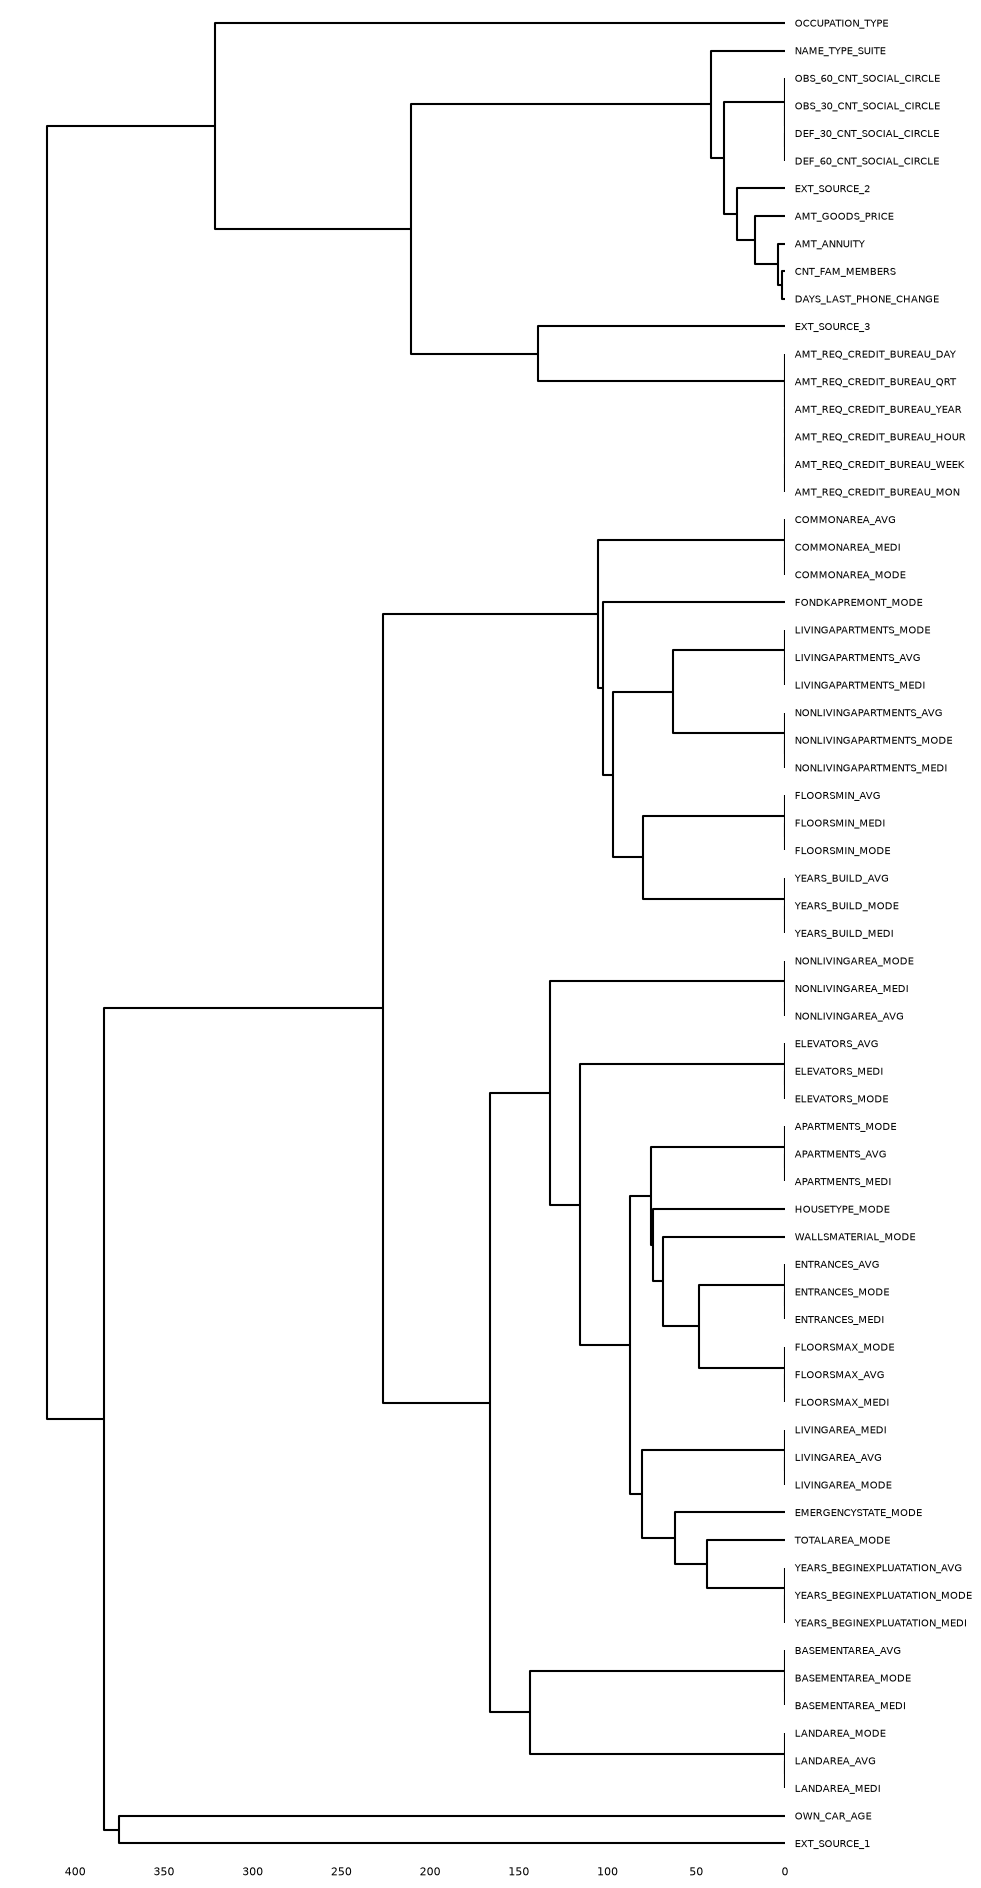

In [20]:
missing_cols = df_missing_cols["col_name"].tolist()

msno.matrix(df[missing_cols].sample(1000,random_state=RANDOM_SEED),figsize=(14,6),fontsize=7,sparkline=False)
plt.show()

msno.heatmap(df[missing_cols],figsize=(14,10),fontsize=7)
plt.show()

msno.dendrogram(df[missing_cols],figsize=(10,24),fontsize=7)
plt.show()

Housing Columns are divided into subgroups, which are not completely but closely correlated to each other.

Credit Bureau columns are strongly positively correlated with each other

Social Circle columns are strongly positively correlated with each other

EXT_SOURCE_3 and Credit Bureau columns overlap in missingness: bureau-missing rows are a subset of EXT_SOURCE_3-missing rows. Their values are not correlated (Spearman -0.02, see below)

## 3.2 Missing vs present: default rate
- For a few important columns or groups (housing, `EXT_SOURCE_1/3`, bureau, `OCCUPATION_TYPE`, `OWN_CAR_AGE`):
  group sizes and `TARGET` rate when missing vs present.
- A gap is an association, not proof that missingness causes default.

**What I see:**

In [21]:
housing_cols = grouped_cols["Housing"]
n_missing_housing = df[housing_cols].isna().sum(axis=1)
n_cols = len(housing_cols)

masks = {
    "all_housing_missing":     n_missing_housing == n_cols,
    "partial_housing_missing": (n_missing_housing > 0) & (n_missing_housing < n_cols),
    "no_housing_missing":      n_missing_housing == 0,
}


rows = []

for name,mask in masks.items():
    g = df.groupby(mask)["TARGET"].agg(["count","mean"])
    rows.append({
        "Missing":name,
        "n_missing":g.loc[True,"count"],
        "rate_missing_%":100 * g.loc[True,"mean"],
        "rate_present_%":100 * g.loc[False,"mean"],
    })

housing_missing = pd.DataFrame(rows)
housing_missing["gap_pts"] = housing_missing["rate_missing_%"] - housing_missing["rate_present_%"]
housing_missing


,Missing,n_missing,rate_missing_%,rate_present_%,gap_pts
0,all_housing_missing,145755,9.260746,7.002522,2.258223
1,partial_housing_missing,83161,7.038155,8.456430,-1.418275
2,no_housing_missing,78595,6.964820,8.453319,-1.488499


all_housing_missing group has gap of **2.26**, while partial_housing_missing and no_housing_missing group have almost similar gap pts of **-1.4** . This presumably could be because people with all_housing_missing group could be renters while people with partial and no housing missing home owners.

In [22]:
other_cols = ["OCCUPATION_TYPE", "OWN_CAR_AGE", "EXT_SOURCE_1", "EXT_SOURCE_3"]

credit_bureau_cols = grouped_cols["AMT_REQ_CREDIT_BUREAU"]
p = df["TARGET"].mean()  
n_missing_housing = df[housing_cols].isna().sum(axis=1)


masks = {
    "OCCUPATION_TYPE": df["OCCUPATION_TYPE"].isna(),
    "OWN_CAR_AGE": df["OWN_CAR_AGE"].isna(),
    "EXT_SOURCE_1": df["EXT_SOURCE_1"].isna(),
    "EXT_SOURCE_2": df["EXT_SOURCE_2"].isna(),
    "EXT_SOURCE_3": df["EXT_SOURCE_3"].isna(),
    "BUREAU (6 cols)": df[credit_bureau_cols[0]].isna(),     # all six share one mask
    "HOUSING: all missing": n_missing_housing == len(housing_cols),
}

rows = []

for name, mask in masks.items():
    g = df.groupby(mask)["TARGET"].agg(["count","mean"])

    rows.append({
        "feature":name,
        "n_missing":g.loc[True,"count"],
        "n_present":g.loc[False,"count"],
        "rate_missing_%":100 * g.loc[True,"mean"],
        "rate_present_%":100 * g.loc[False,"mean"],
    })
    

missing_vs_present = pd.DataFrame(rows)
missing_vs_present["gap_pts"] = missing_vs_present["rate_missing_%"] - missing_vs_present["rate_present_%"]
missing_vs_present["se_pts"] = 100 * (
    p * (1 - p) * (1 / missing_vs_present["n_missing"] + 1 / missing_vs_present["n_present"])
) ** 0.5
missing_vs_present["real"] = missing_vs_present["gap_pts"].abs() > 2 * missing_vs_present["se_pts"]

missing_vs_present.round(2)


,feature,n_missing,n_present,rate_missing_%,rate_present_%,gap_pts,se_pts,real
0,OCCUPATION_TYPE,96391,211120,6.51,8.79,-2.27,0.11,True
1,OWN_CAR_AGE,202929,104582,8.50,7.24,1.26,0.10,True
2,EXT_SOURCE_1,173378,134133,8.52,7.50,1.02,0.10,True
3,EXT_SOURCE_2,660,306851,7.88,8.07,-0.19,1.06,False
4,EXT_SOURCE_3,60965,246546,9.31,7.77,1.55,0.12,True
5,BUREAU (6 cols),41519,265992,10.34,7.72,2.62,0.14,True
6,HOUSING: all missing,145755,161756,9.26,7.00,2.26,0.10,True


- Housing Columns: +2.26pt gap in default rate with 145755 missing rows
- Bureau Columns: +2.62pt gap in default rate with 41519 missing rows
- Occupation Type: -2.27pt gap in default rate with 96391 missing rows
- EXT_SOURCE_3: +1.55pt gap in default rate with 60965 missing rows

Occupation type column is going in the opposite direction, which could be due to applicants being pensioner

## 3.3 Could another feature explain the gap?
- Repeat one comparison inside the groups of a likely explanatory column (for example `NAME_INCOME_TYPE`).
- Does the gap survive inside each group?

**What I see:**

In [23]:
col = "OCCUPATION_TYPE"
check = (
    df.groupby(["NAME_INCOME_TYPE", df[col].isna()])["TARGET"]
      .agg(n="count", default_rate="mean")
)
check["default_rate"] *= 100
check


n  default_rate
NAME_INCOME_TYPE     OCCUPATION_TYPE                      
Businessman          False                 8      0.000000
                     True                  2      0.000000
Commercial associate False             59320      7.648348
                     True              12297      6.692689
Maternity leave      False                 4     50.000000
                     True                  1      0.000000
Pensioner            False                 5      0.000000
                     True              55357      5.386853
State servant        False             17916      5.816030
                     True               3787      5.466068
Student              False                13      0.000000
                     True                  5      0.000000
Unemployed           True                 22     36.363636
Working              False            133854      9.686674
                     True              24920      9.060995

In [24]:

col = "EXT_SOURCE_3"
check = (
    df.groupby(["NAME_INCOME_TYPE", df[col].isna()])["TARGET"]
      .agg(n="count", default_rate="mean")
)
check["default_rate"] *= 100
check


n  default_rate
NAME_INCOME_TYPE     EXT_SOURCE_3                      
Businessman          False              4      0.000000
                     True               6      0.000000
Commercial associate False          56746      7.327389
                     True           14871      8.082846
Maternity leave      True               5     40.000000
Pensioner            False          44309      5.159223
                     True           11053      6.296933
State servant        False          18474      5.559164
                     True            3229      6.875194
Student              False             14      0.000000
                     True               4      0.000000
Unemployed           False              5      0.000000
                     True              17     47.058824
Working              False         126994      9.194923
                     True           31780     11.161108

In [25]:
n_missing_housing = df[housing_cols].isna().sum(axis=1)

mask =  n_missing_housing == len(housing_cols)
check = (
    df.groupby(["NAME_INCOME_TYPE", mask])["TARGET"]
      .agg(n="count", default_rate="mean")
)
check["default_rate"] *= 100
check


n  default_rate
NAME_INCOME_TYPE                               
Businessman          False      9      0.000000
                     True       1      0.000000
Commercial associate False  42413      6.540448
                     True   29204      8.854951
Maternity leave      False      2      0.000000
                     True       3     66.666667
Pensioner            False  28464      4.781478
                     True   26898      6.026470
State servant        False  11063      4.817861
                     True   10640      6.729323
Student              False     11      0.000000
                     True       7      0.000000
Unemployed           False     11     27.272727
                     True      11     45.454545
Working              False  79783      8.342629
                     True   78991     10.846805

The housing, bureau and EXT_SOURCE_3 gaps survive within every large income group (about +1 to +2.5 pts). The occupation gap is mostly a pensioner effect; among non-pensioners it shrinks to about -0.4 to -1 pt.

In [26]:


mask =  df["DAYS_EMPLOYED"] == 365243
check = (
    df.groupby(["NAME_INCOME_TYPE", mask])["TARGET"]
      .agg(n="count", default_rate="mean")
)
check["default_rate"] *= 100
check

n  default_rate
NAME_INCOME_TYPE     DAYS_EMPLOYED                      
Businessman          False              10      0.000000
Commercial associate False           71617      7.484257
Maternity leave      False               5     40.000000
Pensioner            False              10      0.000000
                     True            55352      5.387339
State servant        False           21703      5.754965
Student              False              18      0.000000
Unemployed           True               22     36.363636
Working              False          158774      9.588472

In [27]:
pd.crosstab(df["NAME_INCOME_TYPE"], df["DAYS_EMPLOYED"] == 365243)


DAYS_EMPLOYED,False,True
NAME_INCOME_TYPE,,
Businessman,10,0
Commercial associate,71617,0
Maternity leave,5,0
Pensioner,10,55352
State servant,21703,0
Student,18,0
Unemployed,0,22
Working,158774,0


In [28]:
display(pd.crosstab(df["NAME_INCOME_TYPE"], df["ORGANIZATION_TYPE"] == "XNA"))

print((df["DAYS_EMPLOYED"] == 365243).equals(df["ORGANIZATION_TYPE"] == "XNA"))


ORGANIZATION_TYPE,False,True
NAME_INCOME_TYPE,,
Businessman,10,0
Commercial associate,71617,0
Maternity leave,5,0
Pensioner,10,55352
State servant,21703,0
Student,18,0
Unemployed,0,22
Working,158774,0


True


DAYS_EMPLOYED == 365243 and ORGANIZATION_TYPE == "XNA" mark the same 55,374 rows. Of those, 55,352 are Pensioners (99.98% of pensioners) and 22 are Unemployed. They're placeholders for "no current employer", not real values.

In [29]:
print(df["NAME_INCOME_TYPE"].value_counts(),"\n")
print(f"The EXT_SOURCE_3 missing value baseline",df["EXT_SOURCE_3"].isna().mean().round(2),"The total missing value is",df["EXT_SOURCE_3"].isna().sum(),"\n")
display(pd.crosstab(df["NAME_INCOME_TYPE"], df["EXT_SOURCE_3"].isna(),normalize="index"))
print(f"The EXT_SOURCE_1 missing value baseline",df["EXT_SOURCE_1"].isna().mean().round(2),"The total missing values is",df["EXT_SOURCE_1"].isna().sum(),"\n")
display(pd.crosstab(df["NAME_INCOME_TYPE"], df["EXT_SOURCE_1"].isna(),normalize="index"))



NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64 

The EXT_SOURCE_3 missing value baseline 0.2 The total missing value is 60965 



EXT_SOURCE_3,False,True
NAME_INCOME_TYPE,,
Businessman,0.400000,0.600000
Commercial associate,0.792354,0.207646
Maternity leave,0.000000,1.000000
Pensioner,0.800350,0.199650
State servant,0.851219,0.148781
Student,0.777778,0.222222
Unemployed,0.227273,0.772727
Working,0.799841,0.200159


The EXT_SOURCE_1 missing value baseline 0.56 The total missing values is 173378 



EXT_SOURCE_1,False,True
NAME_INCOME_TYPE,,
Businessman,0.400000,0.600000
Commercial associate,0.501515,0.498485
Maternity leave,0.800000,0.200000
Pensioner,0.232109,0.767891
State servant,0.507902,0.492098
Student,0.500000,0.500000
Unemployed,0.318182,0.681818
Working,0.468080,0.531920


- For **EXT_SOURCE_3** the missingness is similar across the income types. State servant is a little lower at 14.9%, which is 3,229 rows and about 5% of the total missing values in EXT_SOURCE_3, which is not that significant; the flag is not an income-type proxy

- For **EXT_SOURCE_1**, pensioner group has 76.8% (42,512 rows) missingness which is more than the missingness baseline of 56% for the EXT_SOURCE_1. The pensioner group makes 24.5% of the EXT_SOURCE_1 missing rows (173,378).

In [30]:
is_pensioner = df["NAME_INCOME_TYPE"] == "Pensioner"
ext1_missing = df["EXT_SOURCE_1"].isna()

strata = {"pensioner": is_pensioner, "non_pensioner": ~is_pensioner}

rows = []

for name,s in strata.items():
    sub = df[s]
    g = sub.groupby(ext1_missing[s])["TARGET"].agg(["count","mean"])
    p = sub["TARGET"].mean()
    rows.append({
        "stratum":name,
        "n_missing":g.loc[True,"count"],
        "n_present":g.loc[False,"count"],
        "rate_missing_%":100 * g.loc[True,"mean"],
        "rate_present_%":100 * g.loc[False,"mean"],
        "p": p,
    })

out = pd.DataFrame(rows)
out["gap_pts"] = out["rate_missing_%"] - out["rate_present_%"]
out["se_pts"] = 100 * (out["p"] * (1 - out["p"]) * (1 / out["n_missing"] + 1 / out["n_present"])) ** 0.5
out["real"] = out["gap_pts"].abs() > 2 * out["se_pts"]
out


,stratum,n_missing,n_present,rate_missing_%,rate_present_%,p,gap_pts,se_pts,real
0,pensioner,42512,12850,5.452578,5.167315,0.053864,0.285263,0.227260,False
1,non_pensioner,130866,121283,9.515841,7.742223,0.086627,1.773618,0.112116,True


- Pensioners: EXT_SOURCE_1 missing shows no detectable signal for pensioners group

- Non-pensioners: For non-pensioners with missing EXT_SOURCE_1 have higher default rate, showing that EXT_SOURCE_1 missing is informative

In [31]:
display(pd.crosstab(df["AMT_REQ_CREDIT_BUREAU_MON"].isna(), df["EXT_SOURCE_3"].isna(),normalize="index"))
display(pd.crosstab(df["EXT_SOURCE_3"].isna(), df["AMT_REQ_CREDIT_BUREAU_MON"].isna(),normalize="index"))


EXT_SOURCE_3,False,True
AMT_REQ_CREDIT_BUREAU_MON,,
False,0.926893,0.073107
True,0.000000,1.000000


AMT_REQ_CREDIT_BUREAU_MON,False,True
EXT_SOURCE_3,,
False,1.00000,0.00000
True,0.31897,0.68103


In [32]:
df[['AMT_REQ_CREDIT_BUREAU_MON','EXT_SOURCE_3']].corr(method="spearman")

,AMT_REQ_CREDIT_BUREAU_MON,EXT_SOURCE_3
AMT_REQ_CREDIT_BUREAU_MON,1.00000,-0.01896
EXT_SOURCE_3,-0.01896,1.00000


Spearman correlation between `AMT_REQ_CREDIT_BUREAU_MON` and `EXT_SOURCE_3` is **-0.019** (rows where both exist): the values are essentially uncorrelated. The overlap is in the missingness only, so EXT_SOURCE_3 is not a duplicate of the bureau columns in value.

In [33]:
ext3_missing = df["EXT_SOURCE_3"].isna()
bureau_missing = df["AMT_REQ_CREDIT_BUREAU_MON"].isna()

masks = {
    "both_missing":      ext3_missing & bureau_missing,
    "ext3_only_missing": ext3_missing & ~bureau_missing,
    "neither_missing":   ~ext3_missing & ~bureau_missing,
}

rows = []
for name, mask in masks.items():
    g = df.groupby(mask)["TARGET"].agg(["count", "mean"])
    rows.append({
        "Group": name,
        "n_group": g.loc[True, "count"],
        "n_present":g.loc[False,"count"],
        "rate_group_%": 100 * g.loc[True, "mean"],
        "rate_rest_%": 100 * g.loc[False, "mean"],
    })

missing_groups = pd.DataFrame(rows)
missing_groups["gap_pts"] = missing_groups["rate_group_%"] - missing_groups["rate_rest_%"]
missing_groups["se_pts"] = 100 * (
    p * (1 - p) * (1 / missing_groups["n_group"] + 1 / missing_groups["n_present"])
) ** 0.5
missing_groups["real"] = missing_groups["gap_pts"].abs() > 2 * missing_groups["se_pts"]

missing_groups


,Group,n_group,n_present,rate_group_%,rate_rest_%,gap_pts,se_pts,real
0,both_missing,41519,265992,10.337436,7.719405,2.618031,0.148431,True
1,ext3_only_missing,19446,288065,7.122287,8.137052,-1.014765,0.208411,True
2,neither_missing,246546,60965,7.766502,9.311900,-1.545398,0.127231,True


All three groups have clearly different default rates (10.3%, 7.1%, 7.8%). The 3.2 pt gap between both_missing and ext3_only_missing is >10× its standard error, so a single EXT_SOURCE_3 flag would blur two distinct risk groups. Keep both flags.

In [34]:
pd.crosstab(df["OWN_CAR_AGE"].isna(),df["FLAG_OWN_CAR"])

FLAG_OWN_CAR,N,Y
OWN_CAR_AGE,,
False,0,104582
True,202924,5


OWN_CAR_AGE is missing for 202,924 rows, all with FLAG_OWN_CAR = N, and present for 104,582 rows, all with FLAG_OWN_CAR = Y (only 5 car owners 
have no age). Missing means 'no car', so FLAG_OWN_CAR already carries it and no separate flag is needed.

In [35]:
name_type_suite = df["NAME_TYPE_SUITE"].isna()
amt_goods_price = df["AMT_GOODS_PRICE"].isna()
social_circle = df[grouped_cols["SOCIAL_CIRCLE"][0]].isna()

masks = {
    "NAME_TYPE_SUITE": name_type_suite,
    "AMT_GOODS_PRICE": amt_goods_price,
    "SOCIAL_CIRCLE": social_circle
}

rows = []

for name,mask in masks.items():
    g = df.groupby(mask)["TARGET"].agg(["count","mean"])
    rows.append({
        "name": name,
        "n_missing": g.loc[True,"count"],
        "n_present": g.loc[False,"count"],
        "n_missing_%":100 * g.loc[True,"mean"],
        "n_present_%":100 * g.loc[False,"mean"],
    })
    

out = pd.DataFrame(rows)
out["gap_pts"] = out["n_present_%"] - out["n_missing_%"]
out["se_pts"] = 100 * (
    p * (1 - p) * (1 / out["n_missing"] + 1 / out["n_present"])
) ** 0.5
out["real"] = out["gap_pts"].abs() > 2 * out["se_pts"]
out


    

,name,n_missing,n_present,n_missing_%,n_present_%,gap_pts,se_pts,real
0,NAME_TYPE_SUITE,1292,306219,5.417957,8.084084,2.666127,0.784214,True
1,AMT_GOODS_PRICE,278,307233,7.553957,8.073351,0.519395,1.687818,False
2,SOCIAL_CIRCLE,1021,306490,3.525955,8.088029,4.562074,0.881781,True


- "NAME_TYPE_SUITE and SOCIAL_CIRCLE (about 0.3% missing): significant gap (−2.7 and −4.6 pts) but on about 1,000 rows, too few to change the model or to check against income type. Impute (mode / median), no flag by default."

- "AMT_GOODS_PRICE (0.09%): gap within noise → impute."

## 3.4 Tentative decisions
Pick one action per important column or group:
- keep the missing values for now
- impute (with what?)
- treat missing as its own category
- add a missing-value indicator
- consider dropping (little information or redundant)

Do not drop because the percentage is high, or impute because it is low. Nothing is changed in `df` here.

## 3.5 Decision log
Only features that need attention. Keep apart what the data **shows**, what I **suspect**, and what needs **testing in validation**.

In [36]:
decision_log = pd.DataFrame(
    columns=["Feature", "Missing %", "Key finding", "Tentative action", "Reason", "Test in modelling"]
)

rows = [
    [
        "DAYS_EMPLOYED / ORGANIZATION_TYPE (placeholders)", 18.0,
        "365243 and XNA mark the same 55,374 rows: 99.98% of pensioners plus the 22 unemployed (100%). "
        "Default 5.4% vs 8.7%, which is the pensioner effect",
        "Convert 365243 / XNA to NaN on a copy; no missing flag unless validation shows otherwise",
        "Placeholder for 'no current employer', not a real value. It appears only for Pensioners and "
        "Unemployed, so a missing flag would duplicate the Pensioner category",
        "Missing flag vs no flag (expect no gain)",
    ],
    [
        "Housing (47 cols)", 47.4,
        "All 47 missing on 47.4% of rows. Gap +2.26 pts, positive in every large income type "
        "(+1.2 to +2.5). Columns go missing in blocks. Partial and none-missing have similar target rates",
        "One 'all housing missing' flag; keep values as NaN for trees, median fill for linear models",
        "Block pattern with signal that is not explained by income type. "
        "Only the all-missing state carries signal",
        "Flag only vs flag + values vs dropping the values",
    ],
    [
        "AMT_REQ_CREDIT_BUREAU_* (6 cols)", 13.5,
        "All six share one missing mask. Gap +2.62 pts on 41,519 rows. "
        "Bureau-missing rows are a subset of EXT_SOURCE_3-missing rows (100%)",
        "One bureau-missing flag; fill 0 or median for linear models",
        "Largest gap in the table and a clean single block. Together with the EXT_SOURCE_3 flag it "
        "separates 'no bureau record' from 'EXT_SOURCE_3 missing only'",
        "0 vs median fill; flag vs no flag",
    ],
    [
        "OCCUPATION_TYPE", 31.3,
        "Gap -2.27 pts overall, but 55,357 of the missing rows are pensioners (5.4% default). "
        "Non-pensioner gaps are small and negative: Working -0.63, Commercial -0.96, State servant -0.35",
        "Treat missing as its own category ('Missing')",
        "Categorical column, so it needs a value anyway. Much of the headline gap is the pensioner effect",
        "'Missing' category vs dropping the column; does it add anything beyond NAME_INCOME_TYPE",
    ],
    [
        "OWN_CAR_AGE", 66.0,
        "Gap +1.26 pts. Missing for 202,924 rows, all FLAG_OWN_CAR = N; present for 104,582 rows, "
        "all FLAG_OWN_CAR = Y (only 5 car owners lack an age)",
        "Leave as NaN for tree models; no separate flag; fill value + FLAG_OWN_CAR for linear models",
        "Missing means 'no car', so there is nothing to impute and FLAG_OWN_CAR already carries it. "
        "Within-income-type check not done yet",
        "No flag vs flag (expect no gain); fill 0 vs median for linear models",
    ],
    [
        "EXT_SOURCE_3", 19.8,
        "Gap +1.55 pts, positive in every large income type (+0.8 to +2.0). Missing rate is similar "
        "across large income types (about 20%, State servant 14.9%). Bureau-missing rows are a subset of "
        "EXT_SOURCE_3-missing rows. Default rate: both missing 10.3%, EXT_SOURCE_3 only 7.1%, neither 7.8%",
        "Add two flags, ext3_missing and bureau_missing (they encode the three states); "
        "NaN for trees, median fill for linear models",
        "Real signal that survives income type. A strong predictor, so keep the column. "
        "A single EXT_SOURCE_3 flag would blur two groups with opposite signs",
        "No flags vs ext3_missing only vs both flags",
    ],
    [
        "EXT_SOURCE_1", 56.4,
        "Gap +1.02 pts on 173,378 rows; independent of the other EXT_SOURCE gaps. Missing for 76.8% of "
        "pensioners vs about 50% elsewhere. Within strata: non-pensioners +1.77 pts (about 16x SE), "
        "pensioners +0.29 pts (within noise)",
        "Keep the column; add a missing indicator; NaN for trees, median fill for linear models",
        "High missing % alone is not a reason to drop it. The flag is not a pensioner proxy: "
        "the signal sits in non-pensioners",
        "Flag vs no flag by validation AUC; flag vs flag + interaction with non-pensioner",
    ],
    [
        "EXT_SOURCE_2", 0.2,
        "Only 660 rows missing; gap -0.19 pts against a standard error of 1.06, well inside noise",
        "Impute with the median (check skew first); no flag",
        "Too few rows and no gap, so a flag would add nothing. "
        "Fit the imputer on training data only",
        "Median imputation alone vs imputation + flag (expect no gain)",
    ],
    [
        "NAME_TYPE_SUITE", 0.42,
        "1,292 rows missing; default 5.4% vs 8.1%, gap -2.67 pts (about 3.5x SE). Missing applicants default less",
        "Impute with the mode; no flag by default",
        "The gap is real but rests on about 0.4% of rows, so a flag can barely move the model. "
        "Too few rows for a within-income-type check",
        "Flag vs no flag (expect little gain)",
    ],
    [
        "SOCIAL_CIRCLE (4 cols)", 0.33,
        "All four share one missing mask (1,021 rows); default 3.5% vs 8.1%, gap -4.56 pts (about 5.4x SE). "
        "Missing applicants default less",
        "Impute with the median; no flag by default",
        "The gap is real but rests on about 0.3% of rows, so a flag can barely move the model. "
        "Too few rows for a within-income-type check",
        "Flag vs no flag (expect little gain)",
    ],
    [
        "AMT_GOODS_PRICE", 0.09,
        "278 rows missing; gap -0.52 pts against a standard error of 1.63, well inside noise",
        "Impute with the median; no flag",
        "Too few rows and no gap, so a flag would add nothing. Fit the imputer on training data only",
        "None needed",
    ],
]

decision_log = pd.DataFrame(rows, columns=decision_log.columns)
pd.set_option("display.max_colwidth", None)
decision_log

,Feature,Missing %,Key finding,Tentative action,Reason,Test in modelling
0,DAYS_EMPLOYED / ORGANIZATION_TYPE (placeholders),18.00,"365243 and XNA mark the same 55,374 rows: 99.98% of pensioners plus the 22 unemployed (100%). Default 5.4% vs 8.7%, which is the pensioner effect",Convert 365243 / XNA to NaN on a copy; no missing flag unless validation shows otherwise,"Placeholder for 'no current employer', not a real value. It appears only for Pensioners and Unemployed, so a missing flag would duplicate the Pensioner category",Missing flag vs no flag (expect no gain)
1,Housing (47 cols),47.40,"All 47 missing on 47.4% of rows. Gap +2.26 pts, positive in every large income type (+1.2 to +2.5). Columns go missing in blocks. Partial and none-missing have similar target rates","One 'all housing missing' flag; keep values as NaN for trees, median fill for linear models",Block pattern with signal that is not explained by income type. Only the all-missing state carries signal,Flag only vs flag + values vs dropping the values
2,AMT_REQ_CREDIT_BUREAU_* (6 cols),13.50,"All six share one missing mask. Gap +2.62 pts on 41,519 rows. Bureau-missing rows are a subset of EXT_SOURCE_3-missing rows (100%)",One bureau-missing flag; fill 0 or median for linear models,Largest gap in the table and a clean single block. Together with the EXT_SOURCE_3 flag it separates 'no bureau record' from 'EXT_SOURCE_3 missing only',0 vs median fill; flag vs no flag
3,OCCUPATION_TYPE,31.30,"Gap -2.27 pts overall, but 55,357 of the missing rows are pensioners (5.4% default). Non-pensioner gaps are small and negative: Working -0.63, Commercial -0.96, State servant -0.35",Treat missing as its own category ('Missing'),"Categorical column, so it needs a value anyway. Much of the headline gap is the pensioner effect",'Missing' category vs dropping the column; does it add anything beyond NAME_INCOME_TYPE
4,OWN_CAR_AGE,66.00,"Gap +1.26 pts. Missing for 202,924 rows, all FLAG_OWN_CAR = N; present for 104,582 rows, all FLAG_OWN_CAR = Y (only 5 car owners lack an age)",Leave as NaN for tree models; no separate flag; fill value + FLAG_OWN_CAR for linear models,"Missing means 'no car', so there is nothing to impute and FLAG_OWN_CAR already carries it. Within-income-type check not done yet",No flag vs flag (expect no gain); fill 0 vs median for linear models
5,EXT_SOURCE_3,19.80,"Gap +1.55 pts, positive in every large income type (+0.8 to +2.0). Missing rate is similar across large income types (about 20%, State servant 14.9%). Bureau-missing rows are a subset of EXT_SOURCE_3-missing rows. Default rate: both missing 10.3%, EXT_SOURCE_3 only 7.1%, neither 7.8%","Add two flags, ext3_missing and bureau_missing (they encode the three states); NaN for trees, median fill for linear models","Real signal that survives income type. A strong predictor, so keep the column. A single EXT_SOURCE_3 flag would blur two groups with opposite signs",No flags vs ext3_missing only vs both flags
6,EXT_SOURCE_1,56.40,"Gap +1.02 pts on 173,378 rows; independent of the other EXT_SOURCE gaps. Missing for 76.8% of pensioners vs about 50% elsewhere. Within strata: non-pensioners +1.77 pts (about 16x SE), pensioners +0.29 pts (within noise)","Keep the column; add a missing indicator; NaN for trees, median fill for linear models",High missing % alone is not a reason to drop it. The flag is not a pensioner proxy: the signal sits in non-pensioners,Flag vs no flag by validation AUC; flag vs flag + interaction with non-pensioner
7,EXT_SOURCE_2,0.20,"Only 660 rows missing; gap -0.19 pts against a standard error of 1.06, well inside noise",Impute with the median (check skew first); no flag,"Too few rows and no gap, so a flag would add nothing. Fit the imputer on training data only",Median imputation alone vs imputation + flag (expect no gain)
8,NAME_TYPE_SUITE,0.42,"1,292 rows missing; default 5.4% vs 8.1%, gap -2.67 pts (about 3.5x SE). Missing applicants default less",Impute with the mode; no flag by default,"The 

## 3.6 Missing-values summary
- **Overall situation:** 67 of 122 columns have missing values, 41 of them above 50%, and about 97% of rows have at least one, so dropping rows is not an option. Most of it sits in blocks of columns that go missing together (47 housing columns, 6 credit-bureau columns, 4 social-circle columns). Several single columns (`OCCUPATION_TYPE`, `OWN_CAR_AGE`, `EXT_SOURCE_1`, `EXT_SOURCE_3`) are also heavily missing, and two carry placeholders (`DAYS_EMPLOYED`, `ORGANIZATION_TYPE`). Nothing has been changed in `df`.
- **Most important patterns:**
  - Housing: all 47 columns go missing together. The all-missing group defaults +2.26 pts higher, and the gap survives within every large income type.
  - `DAYS_EMPLOYED == 365243` and `ORGANIZATION_TYPE == "XNA"` mark the same 55,374 rows. Of those, 55,352 are Pensioners (99.98% of pensioners) and 22 are Unemployed. They're placeholders for "no current employer", not real values.
  - Credit bureau missing rows are a subset of `EXT_SOURCE_3` missing rows.
  - Non-pensioners with `EXT_SOURCE_1` missing have a higher default rate (+1.77 pts); there is no detectable signal for pensioners.
  - `OWN_CAR_AGE` is missing for 202,924 rows, all with `FLAG_OWN_CAR` = N, and present for 104,582 rows, all with `FLAG_OWN_CAR` = Y (only 5 car owners have no age). Missing means 'no car', so `FLAG_OWN_CAR` already carries it and no separate flag is needed.
- **Main tentative decisions:**
  - Housing: test flag only vs flag + values vs dropping the values.
  - `DAYS_EMPLOYED` / `ORGANIZATION_TYPE`: convert the placeholders to NaN; no missing flag.
  - Credit bureau: one bureau-missing flag; fill 0 or median for linear models.
  - `OCCUPATION_TYPE`: treat missing as its own category.
  - `OWN_CAR_AGE`: NaN for trees; fill value + `FLAG_OWN_CAR` for linear models.
  - `EXT_SOURCE_3`: two flags (`ext3_missing`, `bureau_missing`); NaN for trees, median fill for linear models.
  - `EXT_SOURCE_1`: add a flag; NaN for trees, median fill for linear models.
  - `EXT_SOURCE_2`, social circle, `AMT_GOODS_PRICE`: impute with the median, no flag.
  - `NAME_TYPE_SUITE`: impute with the mode, no flag.
- **Next steps before modelling:**
  - Finish the open checks: within-income-type check for `OWN_CAR_AGE`, fixed small-columns table, compare missing rates in `application_test.csv` with train.
  - Build the preprocessing from the decision log: placeholders to NaN, missing flags, imputers fitted on the training split only.
  - Run the deferred tests in the decision log on the same stratified CV folds, and keep a change only if it beats the fold-to-fold spread.

# 4. Invalid and Inconsistent values

## 4.1 Overview Table: min,max and tail percentiles numeric columns

In [37]:
num = df[numeric_cols].describe(percentiles=[.01,.99]).T
num["max_over_p99"] = num["max"] / num["99%"]
num.sort_values("max_over_p99",ascending=False)

,count,mean,std,min,1%,99%,max,max_over_p99
AMT_REQ_CREDIT_BUREAU_HOUR,265992.0,0.006402,0.083849,0.000000e+00,0.000000,0.000000e+00,4.000000e+00,inf
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.000000e+00,0.000000,0.000000e+00,9.000000e+00,inf
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,2.565000e+04,45000.000000,4.725000e+05,1.170000e+08,247.619048
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.000000e+00,0.000000,2.000000e+00,2.610000e+02,130.500000
OBS_30_CNT_SOCIAL_CIRCLE,306490.0,1.422245,2.400989,0.000000e+00,0.000000,1.000000e+01,3.480000e+02,34.800000
OBS_60_CNT_SOCIAL_CIRCLE,306490.0,1.405292,2.379803,0.000000e+00,0.000000,1.000000e+01,3.440000e+02,34.400000
DEF_30_CNT_SOCIAL_CIRCLE,306490.0,0.143421,0.446698,0.000000e+00,0.000000,2.000000e+00,3.400000e+01,17.000000
DEF_60_CNT_SOCIAL_CIRCLE,306490.0,0.100049,0.362291,0.000000e+00,0.000000,2.000000e+00,2.400000e+01,12.000000
NONLIVINGAPARTMENTS_MODE,93997.0,0.008076,0.046276,0.000000e+00,0.000000,9.730000e-02,1.000000e+00,10.277492
NONLIVINGAPARTMENTS_MEDI,93997.0,0.008651,0.047415,0.000000e+00,0.000000,1.048000e-01,1.000000e+00,9.541985


In [38]:
rows = []
for col in numeric_cols:
    s = df[col].dropna()
    top = s.nlargest(2)
    rows.append({
        "col": col,
        "max": top.iloc[0],
        "second": top.iloc[1],
        "p99": s.quantile(.99),
        "max_over_second": top.iloc[0] / top.iloc[1] if top.iloc[1] != 0 else np.inf,
    })
screen = pd.DataFrame(rows).sort_values("max_over_second", ascending=False)
screen.query("max_over_second > 1")

,col,max,second,p99,max_over_second
9,DAYS_ID_PUBLISH,0.000000e+00,0.000000e+00,-61.000000,inf
65,DAYS_LAST_PHONE_CHANGE,0.000000e+00,0.000000e+00,0.000000,inf
8,DAYS_REGISTRATION,0.000000e+00,0.000000e+00,-50.000000,inf
70,AMT_REQ_CREDIT_BUREAU_QRT,2.610000e+02,1.900000e+01,2.000000,13.736842
61,OBS_30_CNT_SOCIAL_CIRCLE,3.480000e+02,4.700000e+01,10.000000,7.404255
63,OBS_60_CNT_SOCIAL_CIRCLE,3.440000e+02,4.700000e+01,10.000000,7.319149
1,AMT_INCOME_TOTAL,1.170000e+08,1.800009e+07,472500.000000,6.499968
62,DEF_30_CNT_SOCIAL_CIRCLE,3.400000e+01,8.000000e+00,2.000000,4.250000
64,DEF_60_CNT_SOCIAL_CIRCLE,2.400000e+01,7.000000e+00,2.000000,3.428571
66,AMT_REQ_CREDIT_BUREAU_HOUR,4.000000e+00,3.000000e+00,0.000000,1.333333


- For **DAYS_ID_PUBLISH**,**DAYS_LAST_PHONE_CHANGE** and **DAYS_REGISTRATION**  have inf max_over_second value and are false alarms.

- Feature columns to consider:
 **AMT_REQ_CREDIT_BUREAU_QRT**,**OBS_30_CNT_SOCIAL_CIRCLE**,**OBS_60_CNT_SOCIAL_CIRCLE**,**AMT_INCOME_TOTAL**,**AMT_REQ_CREDIT_BUREAU_HOUR** and **AMT_REQ_CREDIT_BUREAU_MON** whose **max_over_second is > 1**.

In [39]:
display(df["AMT_REQ_CREDIT_BUREAU_QRT"].nlargest(10))
display(df["OBS_30_CNT_SOCIAL_CIRCLE"].nlargest(10))
display(df["OBS_60_CNT_SOCIAL_CIRCLE"].nlargest(10))
display(df["AMT_INCOME_TOTAL"].nlargest(10))
display(df["DEF_30_CNT_SOCIAL_CIRCLE"].nlargest(10))
display(df["DEF_60_CNT_SOCIAL_CIRCLE"].nlargest(10))
display(df["AMT_REQ_CREDIT_BUREAU_HOUR"].nlargest(10))
display(df["AMT_REQ_CREDIT_BUREAU_MON"].nlargest(10))

239474    261.0
253541     19.0
3770        8.0
16194       8.0
62052       8.0
127569      8.0
195971      8.0
257728      8.0
289714      8.0
11326       7.0
Name: AMT_REQ_CREDIT_BUREAU_QRT, dtype: float64

148403    348.0
77497      47.0
169517     30.0
280641     30.0
56170      29.0
33480      28.0
68096      27.0
90035      27.0
94870      27.0
114543     27.0
Name: OBS_30_CNT_SOCIAL_CIRCLE, dtype: float64

148403    344.0
77497      47.0
169517     30.0
56170      29.0
280641     29.0
33480      28.0
68096      27.0
90035      27.0
94870      27.0
114543     27.0
Name: OBS_60_CNT_SOCIAL_CIRCLE, dtype: float64

12840     117000000.0
203693     18000090.0
246858     13500000.0
77768       9000000.0
131127      6750000.0
103006      4500000.0
187833      4500000.0
204564      4500000.0
287463      4500000.0
181698      3950059.5
Name: AMT_INCOME_TOTAL, dtype: float64

148403    34.0
198047     8.0
133829     7.0
15392      6.0
95210      6.0
122245     6.0
152554     6.0
174986     6.0
224433     6.0
229377     6.0
Name: DEF_30_CNT_SOCIAL_CIRCLE, dtype: float64

148403    24.0
133829     7.0
198047     6.0
279348     6.0
298686     6.0
2555       5.0
4954       5.0
15392      5.0
32665      5.0
37643      5.0
Name: DEF_60_CNT_SOCIAL_CIRCLE, dtype: float64

153915    4.0
27403     3.0
28848     3.0
55853     3.0
72054     3.0
91374     3.0
110127    3.0
154787    3.0
187365    3.0
261186    3.0
Name: AMT_REQ_CREDIT_BUREAU_HOUR, dtype: float64

253488    27.0
12869     24.0
88209     23.0
266065    22.0
23241     19.0
46939     19.0
235147    19.0
90449     18.0
99711     18.0
129354    18.0
Name: AMT_REQ_CREDIT_BUREAU_MON, dtype: float64

Feature columns:
 - **AMT_REQ_CREDIT_BUREAU_QRT**: 261 is an isolated value then from 19 it steps down to 8 and then it plateaus.
 - **OBS_30/60_CNT_SOCIAL_CIRCLE**/**DEF_30/60_CNT_SOCIAL_CIRCLE**: each has one isolated top value.
 - **AMT_INCOME_TOTAL**: 117M is an isolated value which drops to 18M and then gradually decreases.
 - **AMT_REQ_CREDIT_BUREAU_HOUR/MON**: the values are genuine long tail not one heavy long tail with isolated values.

In [40]:
df.loc[[148403, 239474, 12840, 153915]].T


,148403,239474,12840,153915
SK_ID_CURR,272071,377322,114967,278383
TARGET,0,0,1,0
NAME_CONTRACT_TYPE,Revolving loans,Cash loans,Cash loans,Cash loans
CODE_GENDER,M,F,F,F
FLAG_OWN_CAR,N,N,N,N
FLAG_OWN_REALTY,Y,Y,Y,Y
CNT_CHILDREN,0,1,1,0
AMT_INCOME_TOTAL,202500.0,360000.0,117000000.0,247500.0
AMT_CREDIT,180000.0,1035000.0,562491.0,495000.0
AMT_ANNUITY,9000.0,30393.0,26194.5,25402.5


## 4.2 Invalid and inconsistent values log
Record each suspicious value, what I checked, and what I decided. Separate **errors** (fix or set to NaN) from **genuine extremes** (keep, transform or cap later). Nothing is changed in `df` here; the actions are applied in preprocessing.


In [41]:
quality_log = pd.DataFrame(
    columns=["Feature", "Check / rule", "Rows affected", "Evidence", "Verdict", "Tentative action", "Reason / status"]
)

rows = [
    [
        "AMT_REQ_CREDIT_BUREAU_QRT", "max vs second-largest", 1,
        "261 vs 19 next; p99 = 2. Row 239474",
        "Suspected error",
        "Set to NaN (or clip at train p99.9) via a rule, not by row index",
        "261 enquiries in about two months is not plausible",
    ],
    [
        "OBS_30/60, DEF_30/60_CNT_SOCIAL_CIRCLE", "max vs second-largest", 1,
        "348 / 344 / 34 / 24 vs next 47 / 47 / 8 / 7. All four on row 148403",
        "Suspected error",
        "Set all four cells to NaN together",
        "One record is extreme in four related columns; the 60-day counts include the 30-day ones",
    ],
    [
        "AMT_INCOME_TOTAL", "max vs second-largest + row inspection", 1,
        "117M vs 18M next; p99 = 472,500. Row 12840: Laborer, secondary education, loan 562,491",
        "Suspected error (judgment)",
        "Set to NaN or cap; keep the 18M and lower rows as a genuine tail (log transform later)",
        "Income does not fit the occupation and education in the same row",
    ],
]

quality_log = pd.DataFrame(rows, columns=quality_log.columns)
pd.set_option("display.max_colwidth", None)
quality_log


,Feature,Check / rule,Rows affected,Evidence,Verdict,Tentative action,Reason / status
0,AMT_REQ_CREDIT_BUREAU_QRT,max vs second-largest,1,261 vs 19 next; p99 = 2. Row 239474,Suspected error,"Set to NaN (or clip at train p99.9) via a rule, not by row index",261 enquiries in about two months is not plausible
1,"OBS_30/60, DEF_30/60_CNT_SOCIAL_CIRCLE",max vs second-largest,1,348 / 344 / 34 / 24 vs next 47 / 47 / 8 / 7. All four on row 148403,Suspected error,Set all four cells to NaN together,One record is extreme in four related columns; the 60-day counts include the 30-day ones
2,AMT_INCOME_TOTAL,max vs second-largest + row inspection,1,"117M vs 18M next; p99 = 472,500. Row 12840: Laborer, secondary education, loan 562,491",Suspected error (judgment),Set to NaN or cap; keep the 18M and lower rows as a genuine tail (log transform later),Income does not fit the occupation and education in the same row


## 4.3 Cross-column consistency

In [42]:
emp = df["DAYS_EMPLOYED"] != 365243   # keep the placeholder out of the check

violations = {
    "employed longer than alive":
        emp & (df["DAYS_EMPLOYED"] < df["DAYS_BIRTH"]),
    "family size <= children":
        df["CNT_FAM_MEMBERS"] <= df["CNT_CHILDREN"],
    "goods price > credit":
        df["AMT_GOODS_PRICE"] > df["AMT_CREDIT"],
}
summary = pd.DataFrame({
    "violations": {k: v.sum() for k, v in violations.items()},
})
summary["% of rows"] = 100 * summary["violations"] / len(df)
summary


,violations,% of rows
employed longer than alive,0,0.00000
family size <= children,0,0.00000
goods price > credit,260,0.08455


In [43]:
pd.crosstab(df["NAME_INCOME_TYPE"],df["OCCUPATION_TYPE"])

OCCUPATION_TYPE,Accountants,Cleaning staff,Cooking staff,Core staff,Drivers,HR staff,High skill tech staff,IT staff,Laborers,Low-skill Laborers,Managers,Medicine staff,Private service staff,Realty agents,Sales staff,Secretaries,Security staff,Waiters/barmen staff
NAME_INCOME_TYPE,,,,,,,,,,,,,,,,,,
Businessman,0,0,0,1,0,0,0,0,0,0,7,0,0,0,0,0,0,0
Commercial associate,3970,892,1305,6528,4916,220,3495,204,12763,370,8916,1036,989,324,11104,343,1559,386
Maternity leave,1,0,0,2,0,0,0,0,1,0,0,0,0,0,0,0,0,0
Pensioner,0,2,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0
State servant,729,261,453,6956,815,64,1033,55,1868,25,2142,2585,38,9,186,264,380,53
Student,1,0,0,3,1,0,0,0,5,2,0,0,0,0,0,0,0,1
Working,5112,3498,4188,14080,12871,279,6852,267,40548,1696,10306,4915,1625,418,20811,698,4782,908


NAME_INCOME_TYPE vs OCCUPATION_TYPE: 5 pensioners have an occupation (0.01%); plausible (former or part-time work). Kept, no action.

## 4.3 Zero-variance or near-constant columns

In [44]:
rows = []
p = df["TARGET"].mean()  
for col in df.columns:
    vc = df[col].value_counts(normalize=True,dropna=False)
    top = vc.index[0]

    is_top = df[col].isna() if pd.isna(top) else (df[col] == top)
    rows.append({
        "col":col,
        "n_unique":df[col].nunique(dropna=False),
        "top_value":top,
        "top_share_%":100 * vc.iloc[0],
        "n_minority":(~ is_top).sum(),
        "rate_top_%":100 * df.loc[is_top,"TARGET"].mean(),
        "rate_minority_%":100 * df.loc[~ is_top,"TARGET"].mean()
    })
const = pd.DataFrame(rows).sort_values("top_share_%",ascending=False)
const["gap_pts"] = const["rate_minority_%"] - const["rate_top_%"]
const["n_top"] = len(df) - const["n_minority"]
const["se_pts"] = 100 * (
    p * (1 - p) * (1 / const["n_minority"] + 1 / const["n_top"])
) ** 0.5
const["real"] = const["gap_pts"].abs() > 2 * const["se_pts"]
const.head(20)

,col,n_unique,top_value,top_share_%,n_minority,rate_top_%,rate_minority_%,gap_pts,n_top,se_pts,real
22,FLAG_MOBIL,2,1,99.999675,1,8.072908,0.000000,-8.072908,307510,27.241865,False
106,FLAG_DOCUMENT_12,2,0,99.999350,2,8.072934,0.000000,-8.072934,307509,19.262938,False
104,FLAG_DOCUMENT_10,2,0,99.997724,7,8.073066,0.000000,-8.073066,307504,10.296557,False
96,FLAG_DOCUMENT_2,2,0,99.995773,13,8.071922,30.769231,22.697308,307498,7.555681,True
98,FLAG_DOCUMENT_4,2,0,99.991870,25,8.073538,0.000000,-8.073538,307486,5.448586,False
101,FLAG_DOCUMENT_7,2,0,99.980814,59,8.073455,5.084746,-2.988710,307452,3.546923,False
111,FLAG_DOCUMENT_17,2,0,99.973334,82,8.074385,2.439024,-5.635360,307429,3.008757,False
115,FLAG_DOCUMENT_21,2,0,99.966505,103,8.071033,13.592233,5.521200,307408,2.684666,True
114,FLAG_DOCUMENT_20,2,0,99.949270,156,8.072750,8.333333,0.260584,307355,2.181645,False
113,FLAG_DOCUMENT_19,2,0,99.940490,183,8.073784,6.557377,-1.516407,307328,2.014373,False


- **FLAG_MOBIL**,**FLAG_MOBIL**,**FLAG_DOCUMENT_12**,**_ 10**,**_4**,**_7**,**12**,**_17**,**_20**,**_19** and **_5**: real = False and far too few rows to estimate anything.
- **FLAG_CONT_MOBIL**: 574 rows in the minority, and real = False.
- **FLAG_DOCUMENT_21** (103 rows, +5.5 pts, about 2.1× SE, sign opposite to the other document flags): drop as individual flag; included in document count.
- **REG_REGION_NOT_LIVE_REGION**: 98.5% one value but with a 4,657-row minority at 9.3% against 8.05% (about 3× SE). Keep it. Near-constant isn't the same as useless.
- For larger-minority document flags(_15,_14,_13,_9,_11,_18,_16) all have lower default rates. It suggests that applicants who supplied these documents defaults less. consolidated count feature (documents provided); test count vs individual flags vs both.


# 5. Univariate Analysis

## 5.1 Numerical Analaysis

In [49]:
df_view = df.replace({"DAYS_EMPLOYED":{365243:np.nan}})

In [53]:


rows = []

for col in numeric_cols:
    s = df_view[col].dropna()
    
    rows.append({
        "col":col,
        "n_unique":s.nunique(),
        "missing_%":100 * df_view[col].isna().mean(),
        "zero_%":100 * (s==0).mean(),
        "min":s.min(),
        "median":s.median(),
        "max":s.max(),
        "skew":s.skew()
    })

numerical_col_summary = pd.DataFrame(rows)
numerical_col_summary["abs_skew"] = numerical_col_summary["skew"].abs()

numerical_col_summary.sort_values(by="abs_skew", ascending=False)


,col,n_unique,missing_%,zero_%,min,median,max,skew,abs_skew
1,AMT_INCOME_TOTAL,2548,0.000000,0.000000,2.565000e+04,147150.000000,1.170000e+08,391.559654,391.559654
70,AMT_REQ_CREDIT_BUREAU_QRT,11,13.501631,80.986270,0.000000e+00,0.000000,2.610000e+02,134.365776,134.365776
67,AMT_REQ_CREDIT_BUREAU_DAY,9,13.501631,99.440209,0.000000e+00,0.000000,9.000000e+00,27.043505,27.043505
44,NONLIVINGAPARTMENTS_MODE,167,69.432963,63.039246,0.000000e+00,0.000000,1.000000e+00,16.251819,16.251819
58,NONLIVINGAPARTMENTS_MEDI,214,69.432963,59.679564,0.000000e+00,0.000000,1.000000e+00,15.671995,15.671995
48,YEARS_BEGINEXPLUATATION_MEDI,245,48.781019,0.347928,0.000000e+00,0.981600,1.000000e+00,-15.573124,15.573124
30,NONLIVINGAPARTMENTS_AVG,386,69.432963,58.032703,0.000000e+00,0.000000,1.000000e+00,15.541185,15.541185
20,YEARS_BEGINEXPLUATATION_AVG,285,48.781019,0.326341,0.000000e+00,0.981600,1.000000e+00,-15.515264,15.515264
34,YEARS_BEGINEXPLUATATION_MODE,221,48.781019,0.090156,0.000000e+00,0.981600,1.000000e+00,-14.755318,14.755318
66,AMT_REQ_CREDIT_BUREAU_HOUR,5,13.501631,99.388703,0.000000e+00,0.000000,4.000000e+00,14.534062,14.534062


Univariate numeric summary (n = 307,511)

1. Isolated outliers (one point far from the rest; check max vs nlargest(10))
   AMT_INCOME_TOTAL (max 117M), AMT_REQ_CREDIT_BUREAU_QRT (max 261),
   OBS_30/60_CNT_SOCIAL_CIRCLE (max 348/344)
   Plot: income -> log-x hist + box plot; QRT -> bar chart, log y;
         OBS_30/60 -> hist, integer bins, log y (33 unique values)
   Later: cap, or flag; trees unaffected

2. Zero-inflated (spike at exactly 0; flag with zero_% > ~30%)
   Counts: AMT_REQ_CREDIT_BUREAU_HOUR/DAY/WEEK/MON/QRT (81-99% zeros),
           DEF_30/60_CNT_SOCIAL_CIRCLE (88-92%), CNT_CHILDREN (70%),
           OBS_30/60_CNT_SOCIAL_CIRCLE (53%)
     Plot: bar chart (OBS_30/60: hist, integer bins, log y)
   Housing: NONLIVINGAPARTMENTS (59-63%), ELEVATORS (60-62%), NONLIVINGAREA (43-49%)
     Plot: hist, log y (log x can't show zeros)
   Later: yes/no flag ("any"), not log or cap
   Note: QRT and OBS_30/60 also appear in group 1 (the groups overlap)

3. Strong right tails (skew 1-2.7, continuous, few zeros)
   AMT_INCOME_TOTAL, AMT_CREDIT, AMT_ANNUITY, AMT_GOODS_PRICE,
   REGION_POPULATION_RELATIVE †, OWN_CAR_AGE (also 66% missing, max 91)
   Plot: hist, log x
   Later: log1p for linear models; income also in group 1
   Moderate-strong counts †: CNT_FAM_MEMBERS (0.99, max 20),
   AMT_REQ_CREDIT_BUREAU_YEAR (1.24, 27% zeros) -> hist, integer bins, log y

4. Housing, other (bounded 0-1, few zeros, mass near 0 or 1)
   Right: LANDAREA, BASEMENTAREA, COMMONAREA, LIVINGAREA, APARTMENTS, ...
   Left †: YEARS_BEGINEXPLUATATION (-15.5), YEARS_BUILD (-1.0)
   Missing 48-70%; _AVG/_MODE/_MEDI redundant -> plot one per base measure
   Plot: hist, log y

5. DAYS_* columns
   DAYS_EMPLOYED: 365243 placeholder already set to NaN (18% missing)
   Convert to years and recompute skew; signs flip
   (EMPLOYED -1.97, LAST_PHONE_CHANGE -0.71, REGISTRATION -0.59 become positive)
   Plot: hist in years

6. Moderate skew †
   EXT_SOURCE_2 (-0.79); no transform
   Plot: hist + box plot

7. Near symmetric (|skew| < 0.5), no action
   EXT_SOURCE_1/3, DAYS_BIRTH, DAYS_ID_PUBLISH, HOUR_APPR_PROCESS_START,
   REGION_RATING_CLIENT / _W_CITY
   Plot: hist + box plot for EXT_SOURCE_1/3; bar chart for the rest


In [63]:

def _grid(df, cols, draw, ncols=3):
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.5*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        draw(ax, df[col].dropna(), col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    fig.tight_layout(); plt.show()

def hist_logx(df, cols, bins=40, ncols=3):
    def draw(ax, s, col):
        s = s[s > 0]                                   # zeros can't sit on a log axis
        ax.hist(s, bins=np.logspace(np.log10(s.min()), np.log10(s.max()), bins))
        ax.set_xscale("log"); ax.set_title(f"{col}  (n={len(s):,})")
    _grid(df, cols, draw, ncols)

def hist_logy(df, cols, integer_bins=False, bins=40, ncols=3):
    def draw(ax, s, col):
        b = np.arange(s.min(), s.max() + 2) - 0.5 if integer_bins else bins
        ax.hist(s, bins=b); ax.set_yscale("log"); ax.set_title(f"{col}  (n={len(s):,})")
    _grid(df, cols, draw, ncols)

def hist_plain(df, cols, years=False, bins=40, ncols=3):
    def draw(ax, s, col):
        if years:
            s = -s[s != 365243] / 365                  # DAYS_* -> positive years, drop placeholder
        ax.hist(s, bins=bins); ax.set_title(f"{col}  (n={len(s):,})")
    _grid(df, cols, draw, ncols)

def box(df, cols, logx=False, ncols=3):
    def draw(ax, s, col):
        ax.boxplot(s, vert=False, flierprops=dict(markersize=2))
        if logx: ax.set_xscale("log")
        ax.set_title(col)
    _grid(df, cols, draw, ncols)

def bar_counts(df, cols, log_y=False, ncols=3):
    def draw(ax, s, col):
        vc = s.value_counts().sort_index()
        ax.bar(vc.index.astype(str), vc.values)
        if log_y: ax.set_yscale("log")
        ax.tick_params(axis="x", rotation=90); ax.set_title(col)
    _grid(df, cols, draw, ncols)


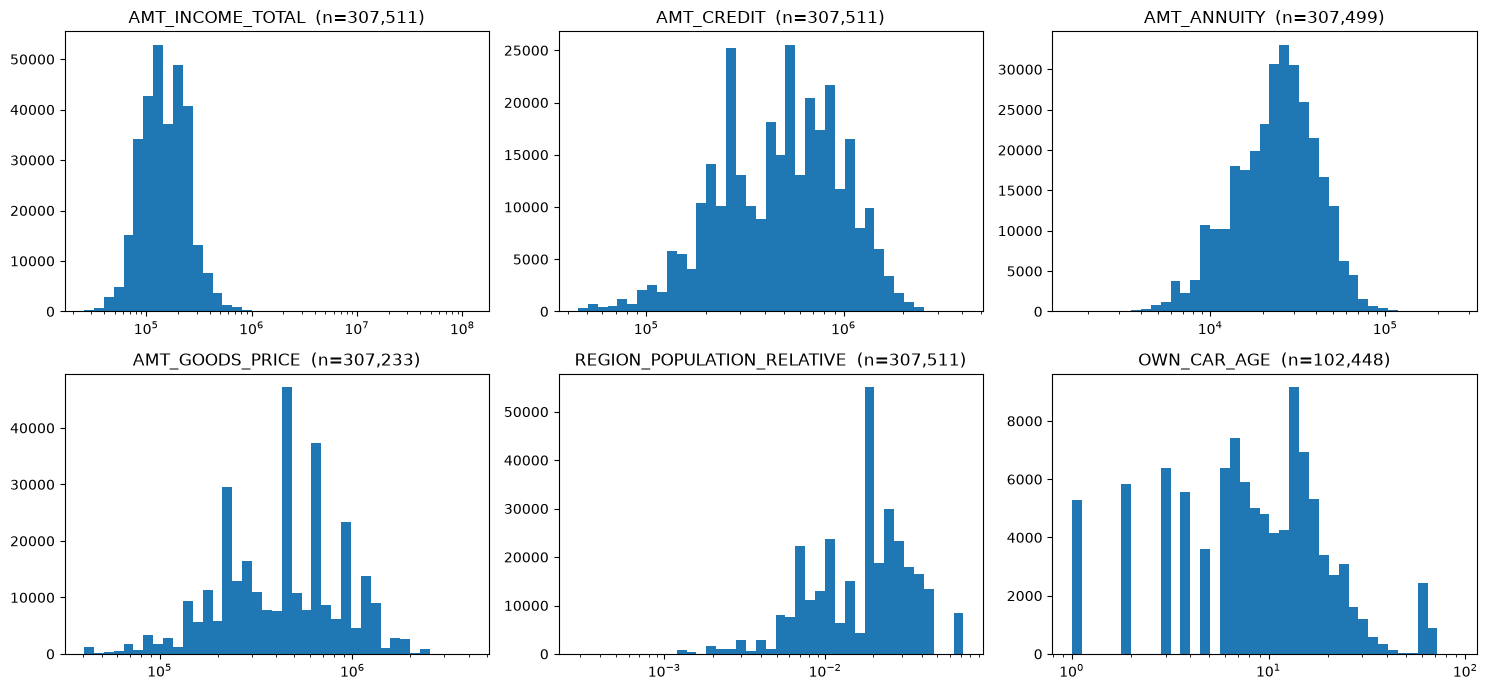

C:\Users\Aditya\AppData\Local\Temp\ipykernel_20196\166422660.py:33: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, flierprops=dict(markersize=2))


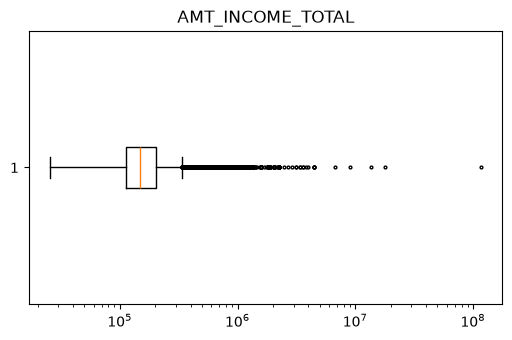

C:\Users\Aditya\AppData\Local\Temp\ipykernel_20196\166422660.py:33: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, flierprops=dict(markersize=2))
C:\Users\Aditya\AppData\Local\Temp\ipykernel_20196\166422660.py:33: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, flierprops=dict(markersize=2))
C:\Users\Aditya\AppData\Local\Temp\ipykernel_20196\166422660.py:33: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(s, vert=False, flierprops=dict(markersize=2))


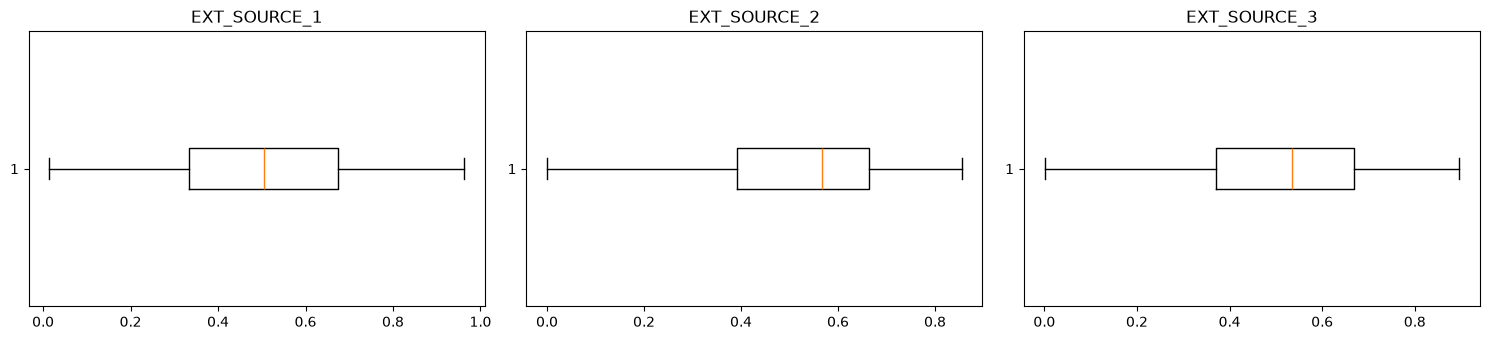

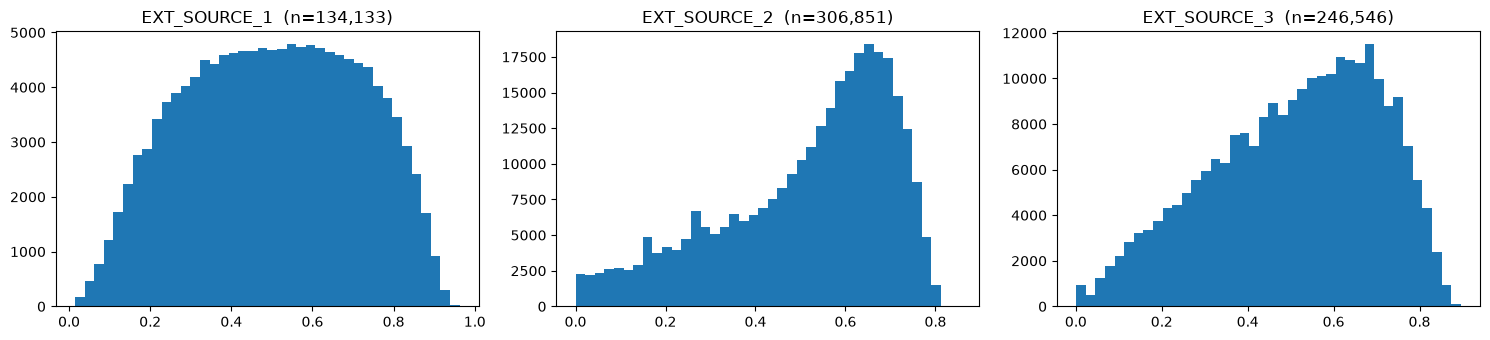

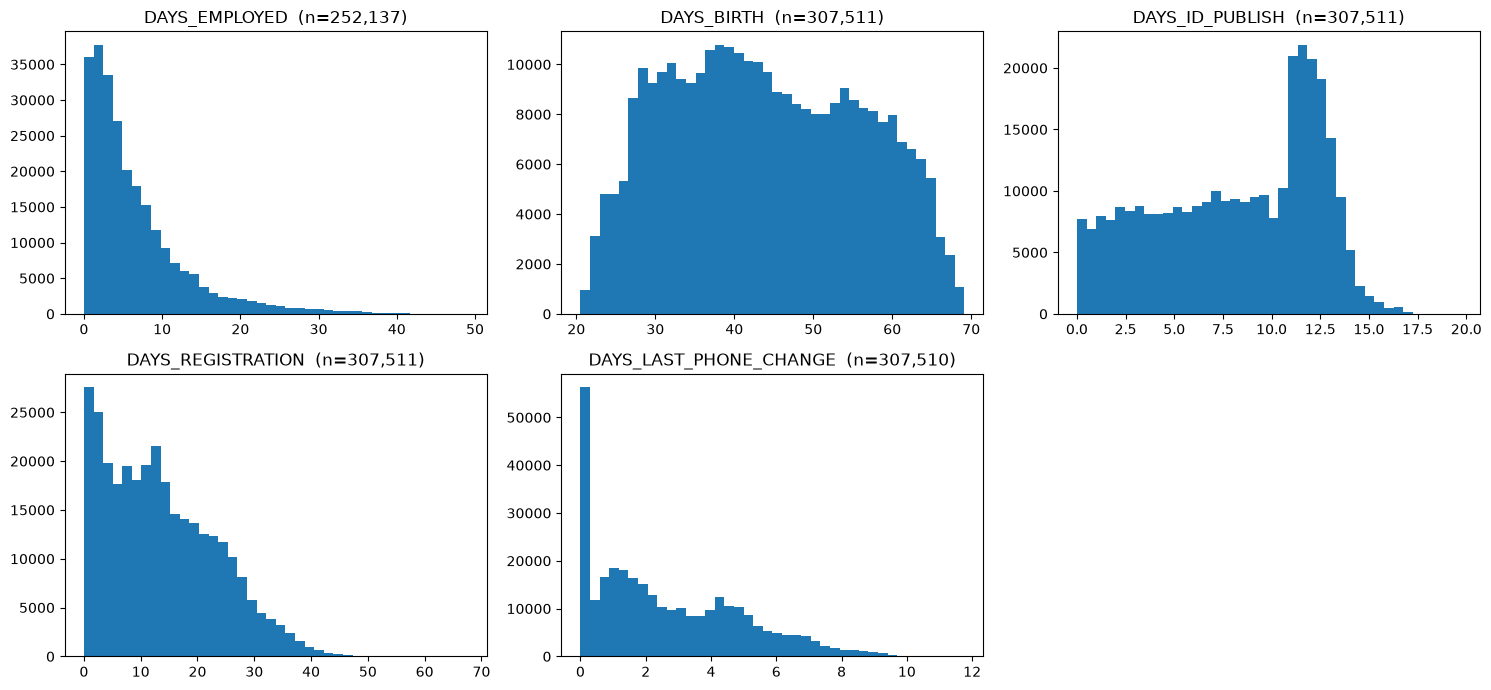

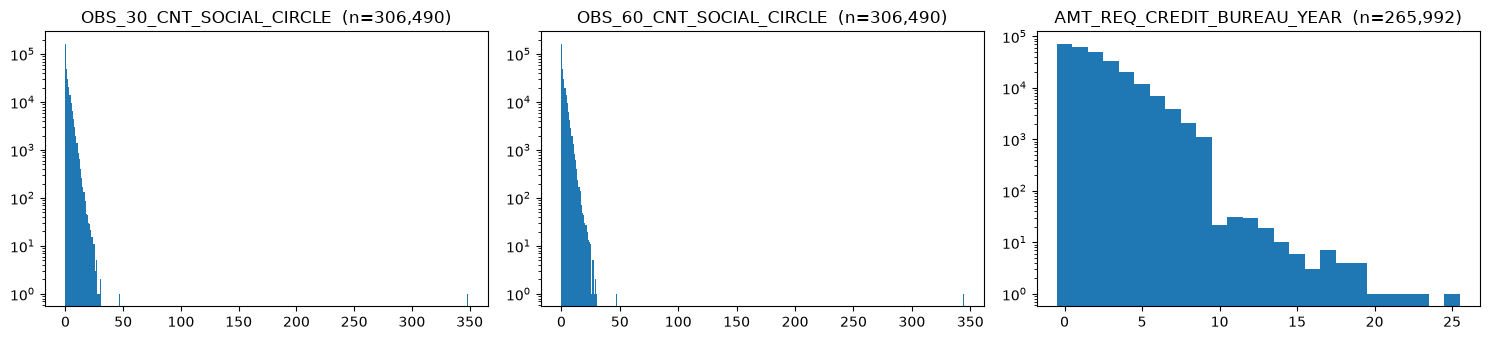

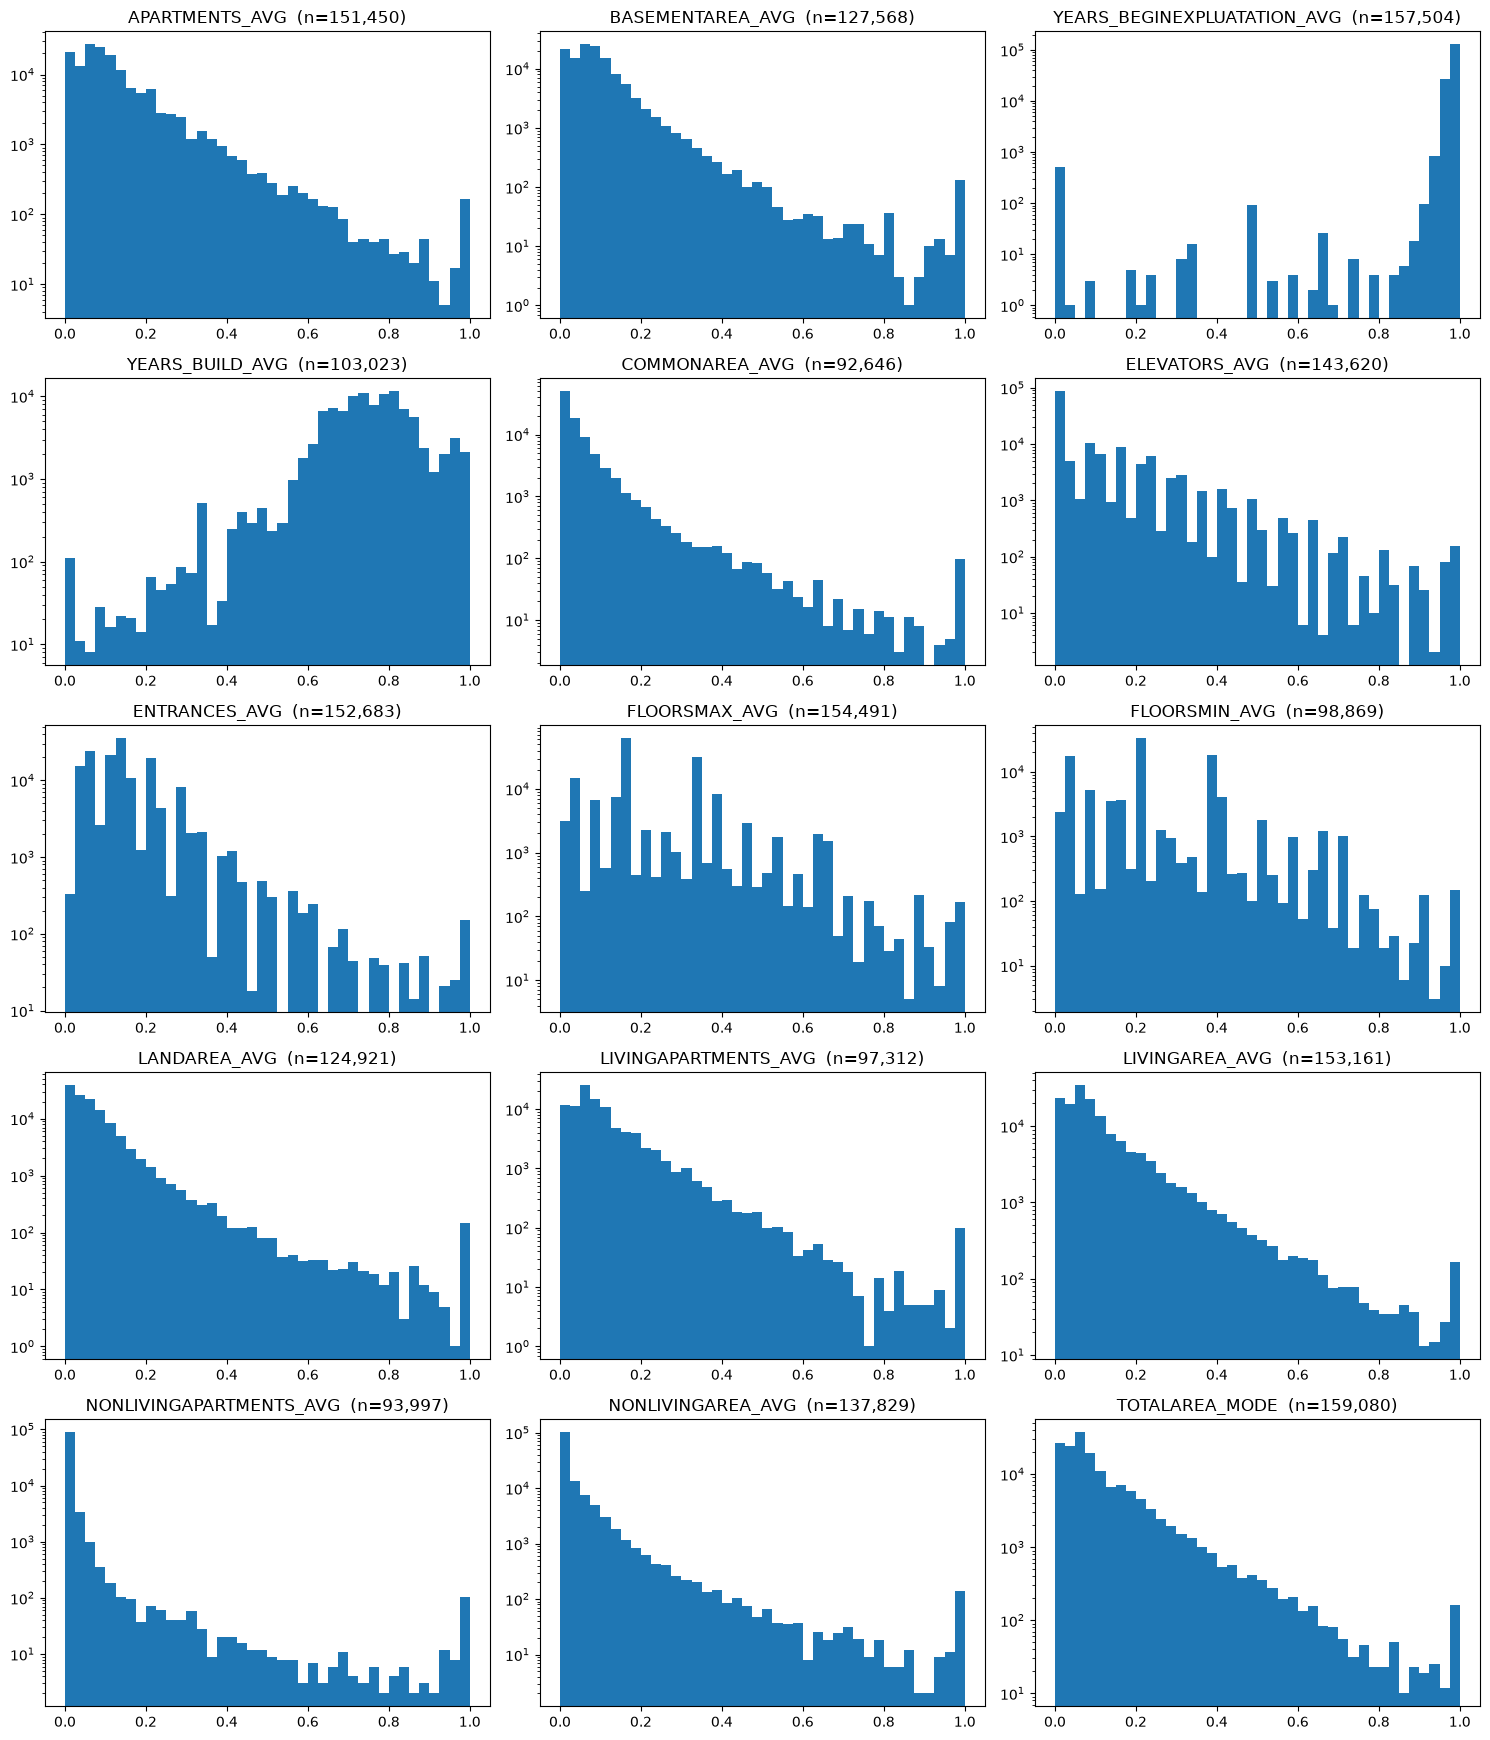

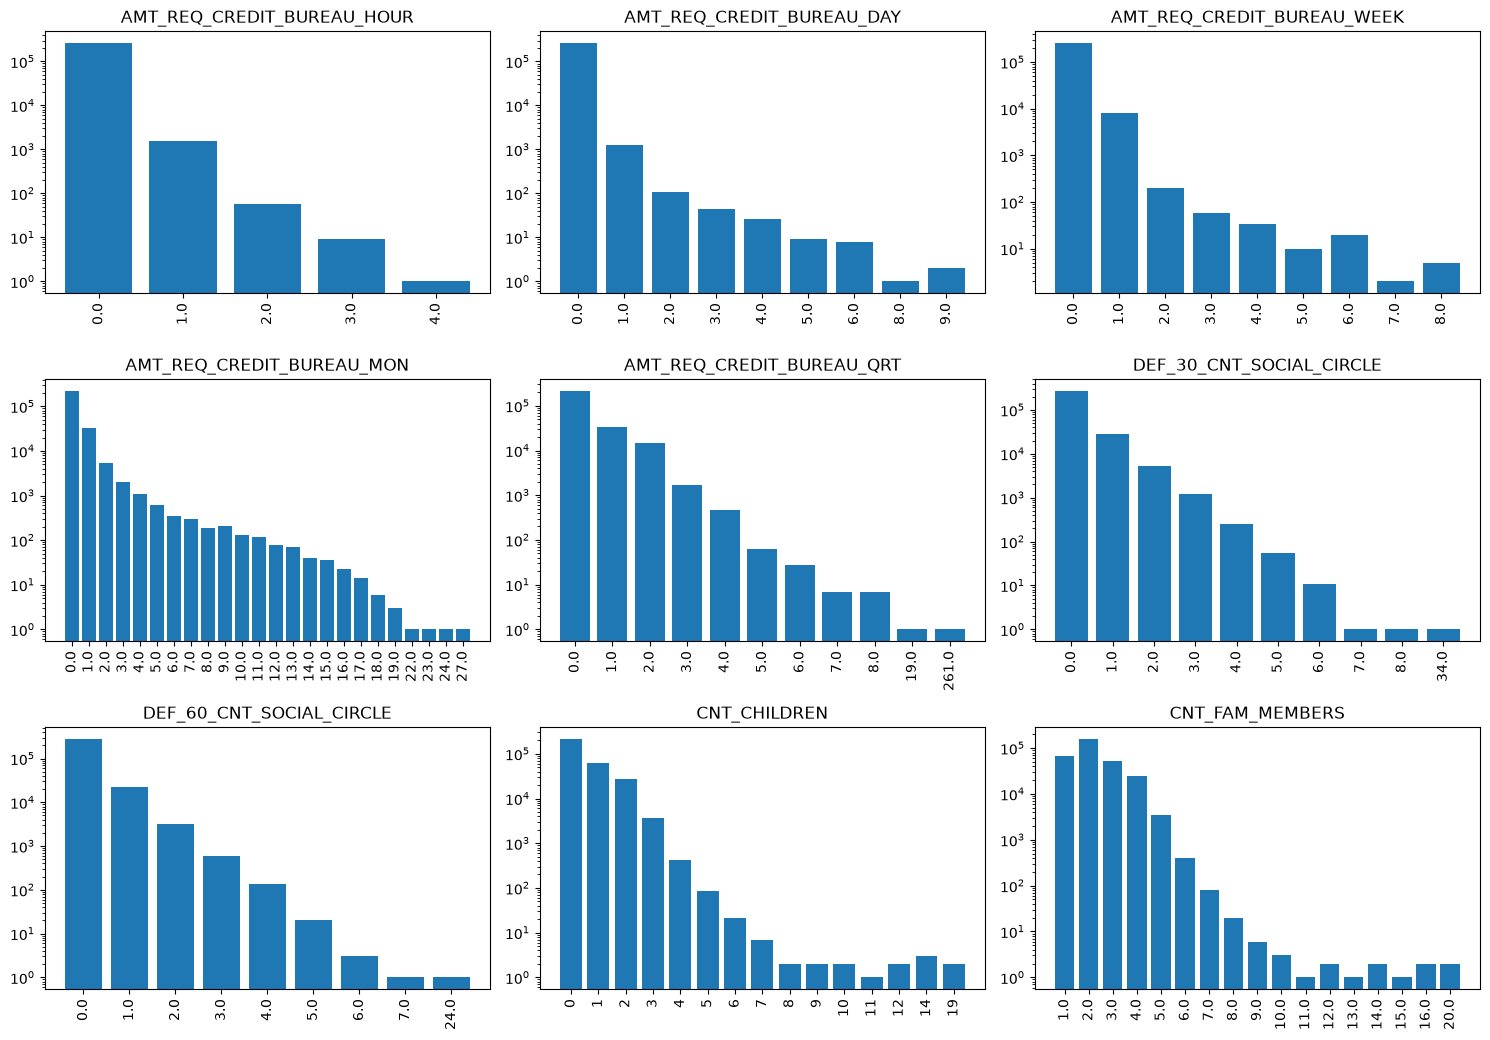

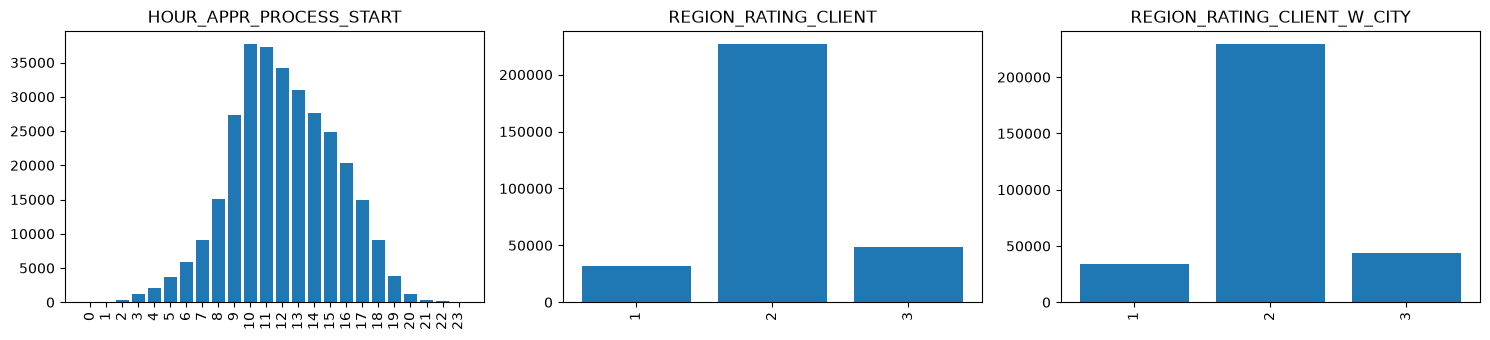

In [68]:
hist_logx(df_view,["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "REGION_POPULATION_RELATIVE", "OWN_CAR_AGE"])
box(df_view,["AMT_INCOME_TOTAL"],True)
box(df_view,["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"])
hist_plain(df_view,["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"])
hist_plain(df_view,["DAYS_EMPLOYED", "DAYS_BIRTH", "DAYS_ID_PUBLISH", "DAYS_REGISTRATION", "DAYS_LAST_PHONE_CHANGE"],True)
hist_logy(df_view,["OBS_30_CNT_SOCIAL_CIRCLE", "OBS_60_CNT_SOCIAL_CIRCLE", "AMT_REQ_CREDIT_BUREAU_YEAR"],integer_bins=True)
hist_logy(df_view,["APARTMENTS_AVG", "BASEMENTAREA_AVG", "YEARS_BEGINEXPLUATATION_AVG", "YEARS_BUILD_AVG", "COMMONAREA_AVG", "ELEVATORS_AVG", "ENTRANCES_AVG", "FLOORSMAX_AVG", "FLOORSMIN_AVG", "LANDAREA_AVG", "LIVINGAPARTMENTS_AVG", "LIVINGAREA_AVG", "NONLIVINGAPARTMENTS_AVG", "NONLIVINGAREA_AVG", "TOTALAREA_MODE"])
bar_counts(df_view,["AMT_REQ_CREDIT_BUREAU_HOUR", "AMT_REQ_CREDIT_BUREAU_DAY", "AMT_REQ_CREDIT_BUREAU_WEEK","AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "DEF_30_CNT_SOCIAL_CIRCLE", "DEF_60_CNT_SOCIAL_CIRCLE", "CNT_CHILDREN", "CNT_FAM_MEMBERS"],log_y=True)
bar_counts(df_view,["HOUR_APPR_PROCESS_START", "REGION_RATING_CLIENT", "REGION_RATING_CLIENT_W_CITY"])
